> **In this repository.** The one-shot test of the two final models. It retrains the DINOv3 ViT-S/16 configuration on train + val, scores `test.csv` once with it and with BioCLIP 2 zero-shot (each at the threshold tuned on validation), times both, and scores `test_unseen.csv`. Its script version is in `src/invasive_clf/`: `train_dinov3.py` for the training. It was run on Google Colab against the team's Google Drive, so its paths point to Drive; the saved outputs are the record of what it produced. To re-run it from this repository, change the data path to the folder made by `src/invasive_clf/data/download_images.py` (see `data/README.md`).

# Final models: training on train + val and the one-shot test set evaluation

This notebook closes the modeling phase. `18_final_model_comparison.ipynb` chose one model per series on validation metrics and wrote the choice to `modeling_runs/final_selection/final_models.json`. This notebook

1. **re-trains the fine-tuned model** (the DINOv3 ViT-S/16 configuration) on **train + val**, with exactly the hyperparameters its experiment notebook converged on, for the full schedule;
2. **scores `test.csv` once** with this model and with the chosen BioCLIP 2 model (frozen features, zero-shot over the saved vocabulary; nothing is trained), each run **timed**, and records every metric of the experiment notebooks at the threshold tuned on validation;
3. tabulates **accuracy against inference runtime**;
4. scores **`test_unseen.csv`** (photos of species the models never saw, all `not_invasive`) and reports the top-1 accuracy, i.e. the share of those photos that is left unflagged.

`test.csv` and `test_unseen.csv` are read here for the first time. Nothing in this notebook is tuned on them: hyperparameters, epochs and thresholds all come from the validation phase.

## How the notebook is organized

* **Section 1** configures paths, the output folder and the evaluation (batch size, timing repeats).
* **Section 2** finds the dataset and `modeling_runs/`, reads `final_models.json`, loads the four CSVs and **describes the split** (sizes, class and group distributions), then decodes every image once into RAM.
* **Sections 3 to 5** are the shared code of the experiment notebooks (backbone adapters, classifier, dataset and transforms, metrics, plots), copied so that the numbers are computed exactly as on validation.
* **Section 6** is the training loop without a validation set: two stages (frozen head, then full fine-tuning with the 1-cycle schedule), the final weights are kept.
* **Section 7** trains the fine-tuned model on train + val. **Section 8** loads the frozen BioCLIP 2 model. **Section 9** builds one scorer per model: a function from a batch of cached uint8 images to the 40 invasive-class probabilities, mirror-TTA included.
* **Section 10** is the timed test set evaluation; **Section 11** the results tables and plots; **Section 12** accuracy versus runtime; **Section 13** the unseen-species set; **Section 14** writes `modeling_runs/final_test/final_results.json`.

## Task encoding (unchanged)

40 invasive-class logits, multi-label BCE, `not_invasive` = all-zero target (index 40). A photo is flagged as invasive when `max_c p_c >= t`, and labeled `argmax_c` then; otherwise `not_invasive`. `t` is the threshold the chosen run tuned on validation (`threshold_val` in `final_models.json`); it is **not** re-tuned here because the retrained models have no held-out data left. Primary metric: macro-F1 over the 40 invasive classes; KPI: top-1 accuracy over the 41 labels.

## Outputs

`modeling_runs/final_test/`: `split_overview.csv`, `class_counts.csv` and the split figures; one folder per series (`config.json`, `history.csv`, `final.pt`, `training_curves.png` for the fine-tuned one; `test_predictions.csv`, `test_probs.npz`, `metrics_test.json`, `pr_roc.png`, `confusion_matrix.png`, `per_class_f1.png`, `unseen_predictions.csv` for both); `test_metrics.csv`, `test_vs_val.csv`, `timing.csv`, `accuracy_vs_runtime.csv`, `unseen_results.csv`, the figures, and `final_results.json` with everything in one place.

## 0. Environment

In [1]:
import importlib.util, os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")

# Install what is missing (Colab ships torch/torchvision/sklearn/pandas/matplotlib/joblib already).
_required = {"torchmetrics": "torchmetrics", "timm": "timm", "huggingface_hub": "huggingface_hub",
             "transformers": "transformers>=4.57.3", "open_clip": "open_clip_torch", "joblib": "joblib"}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# DINOv3 needs transformers >= 4.57.3. Upgrade if the class is absent.
import transformers
if importlib.util.find_spec("transformers.models.dinov3_vit") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.57.3"])
    print("transformers upgraded; RESTART THE RUNTIME and run again.")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import copy, datetime, json, math, random, re, shutil, time, warnings
from dataclasses import dataclass
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.transforms import v2
import torchmetrics
from torchmetrics.classification import MulticlassF1Score, MulticlassAccuracy, MulticlassConfusionMatrix
from tqdm.auto import tqdm
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16
DEVICE_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | torchmetrics {torchmetrics.__version__}")
print(f"device: {DEVICE} ({DEVICE_NAME}) | mixed-precision dtype: {AMP_DTYPE if DEVICE.type == 'cuda' else 'disabled (CPU)'}")
if DEVICE.type == "cuda":
    print(f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")

# Plot style shared by every notebook so figures are comparable across models.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
C_BLUE, C_ORANGE, C_GRAY = "#2a78d6", "#eb6834", "#9a9995"
SERIES_COLORS = {"bioclip2": "#2f9e6e", "finetune": "#2a78d6"}   # one color per model (keyed by series) in every figure
GROUP_COLORS = {"invasive": "#eb6834", "native_background": "#2a78d6", "introduced_unlisted": "#9452d6",
                "listed_not_invasive": "#2f9e6e", "native_listed": "#0e9bb8", "holdout_unseen": "#9a9995"}

def seed_everything(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

torch 2.11.0+cu130 | transformers 5.22.0 | torchmetrics 1.9.0
device: cuda (Tesla T4) | mixed-precision dtype: torch.bfloat16
14.6 GiB


## 1. Configuration

Nothing model-specific is set here: the hyperparameters of the fine-tuned model and the saved weights of the frozen one come from `final_models.json`. Leave the overrides as `None` to use the Team Drive paths on Colab or the repo-relative paths locally.

In [3]:
DATA_ROOT_OVERRIDE = None                 # e.g. "/path/to/downloaded_data/inat_dataset_final"
RUNS_DIR_OVERRIDE = None                  # e.g. "/path/to/modeling_runs"; default: <repo root>/modeling_runs
SELECTION_SUBFOLDER = "final_selection"   # written by 18_final_model_comparison.ipynb; read here
OUTPUT_SUBFOLDER = "final_test"           # written here, under RUNS_DIR

RETRAIN = False                           # False: a fine-tuned model whose final.pt already exists in final_test/<series>/ is loaded, not retrained
EVAL_BATCH_SIZE = 128                     # the same for every model, so the timings are comparable (reduce if the GPU runs out of memory)
TIMING_REPEATS = 1                        # timed passes over the test set per model; > 1 reports the minimum and the mean

SCALAR_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
                  "threshold", "bin_precision_invasive", "bin_recall_invasive", "bin_f1_invasive", "bin_ap_invasive",
                  "bin_auroc_invasive", "noninv_precision", "noninv_recall", "noninv_auroc", "macro_f1_all41"]
KEY_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
               "bin_precision_invasive", "bin_recall_invasive", "bin_auroc_invasive", "noninv_auroc", "threshold"]
NONE_LABEL = "not_invasive"

## 2. Paths, the chosen models and the data

The dataset folder is `DATA_ROOT_OVERRIDE` if set, else the Team Drive path on Colab, else the repo-relative path; `modeling_runs/` is found the same way. `final_models.json` names one model per series: `test_protocol` `"finetune"` (trained again here on train + val with `hyperparameters`) or `"frozen"` (`weights_file` is loaded and scored as it is).

In [4]:
_candidates = [DATA_ROOT_OVERRIDE,
               "/content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "/content/drive/Shareddrives/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "../../downloaded_data/inat_dataset_final", "downloaded_data/inat_dataset_final"]
DATA_ROOT = next((Path(p) for p in _candidates if p and (Path(p) / "train.csv").exists()), None)
assert DATA_ROOT is not None, f"dataset folder not found; tried {_candidates}"
RUNS_DIR = Path(RUNS_DIR_OVERRIDE) if RUNS_DIR_OVERRIDE else DATA_ROOT.parent.parent / "modeling_runs"
SEL_DIR = RUNS_DIR / SELECTION_SUBFOLDER
OUT_DIR = RUNS_DIR / OUTPUT_SUBFOLDER
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert (SEL_DIR / "final_models.json").exists(), f"run 18_final_model_comparison.ipynb first: {SEL_DIR / 'final_models.json'} not found"
print("DATA_ROOT:", DATA_ROOT.resolve()); print("RUNS_DIR :", RUNS_DIR.resolve()); print("OUT_DIR  :", OUT_DIR.resolve())

FINAL = json.load(open(SEL_DIR / "final_models.json"))
MODELS = {s: rec for s, rec in FINAL["models"].items() if rec is not None}        # series -> record, in the comparison's display order
KIND_WORDS = {"finetune": "fine-tuned", "zeroshot": "zero-shot", "knn": "kNN", "knn+zeroshot": "kNN + zero-shot", "logreg": "linear probe"}
MODEL_NAMES = {s: f"{rec.get('backbone_display') or rec['backbone']} ({KIND_WORDS.get(rec['kind'], rec['kind'])})" for s, rec in MODELS.items()}   # names in figures and tables
print(f"\nfinal_models.json written {FINAL['selected_at'][:16]} from {FINAL['runs_dir']}")
for s, rec in MODELS.items():
    print(f"  {s:<9} {MODEL_NAMES[s]}  [{rec['label']}]\n            {rec['candidate']}  ({rec['kind']}, {rec['test_protocol']}; chosen by {rec['chosen_by']})"
          f"  val macro-F1 {rec['metrics']['macro_f1_invasive']:.4f}, top-1 {rec['metrics']['top1_acc_all']:.4f}, threshold {rec['threshold_val']:.2f}")
missing = [s for s in FINAL["models"] if FINAL["models"][s] is None]
if missing:
    print("series with nothing run (skipped):", missing)
FINETUNE_SERIES = [s for s, r in MODELS.items() if r["test_protocol"] == "finetune"]
FROZEN_SERIES = [s for s, r in MODELS.items() if r["test_protocol"] == "frozen"]
assert all(r["kind"] == "finetune" for s, r in MODELS.items() if s in FINETUNE_SERIES), "a 'finetune' series must carry a fine-tune run"


def run_path(rel: str) -> Path:
    # run_dir / weights_file in final_models.json are relative to the modeling_runs folder the comparison ran on
    p = Path(rel)
    return p if p.is_absolute() and p.exists() else RUNS_DIR / rel

DATA_ROOT: /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final
RUNS_DIR : /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/modeling_runs
OUT_DIR  : /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/modeling_runs/final_test

final_models.json written 2026-11-06T02:44 from /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/modeling_runs
  bioclip2  BioCLIP 2 ViT-L/14 (zero-shot)  [BioCLIP 2 (frozen features, no fine-tuning)]
            bioclip2_zeroshot_full/00_baseline  (zeroshot, frozen; chosen by SERIES['bioclip2']['override'])  val macro-F1 0.9668, top-1 0.9823, threshold 0.06
  finetune  DINOv3 ViT-S/16 (fine-tuned)  [fine-tuned models]
            dinov3_vits16/04_pool_cls_patchmean  (finetune, finetune; chosen by SERIES['finetune']['override']

In [5]:
SPLITS = ["train", "val", "test", "test_unseen"]
dfs = {name: pd.read_csv(DATA_ROOT / f"{name}.csv") for name in SPLITS}
train_df, val_df, test_df, unseen_df = (dfs[s] for s in SPLITS)

INVASIVE_CLASSES = sorted(c for c in train_df["label"].unique() if c != NONE_LABEL)
N_INVASIVE = len(INVASIVE_CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(INVASIVE_CLASSES)}
CLASS_TO_IDX[NONE_LABEL] = N_INVASIVE                   # index N_INVASIVE = not_invasive (no logit, only a target)
ALL_LABELS = INVASIVE_CLASSES + [NONE_LABEL]            # 41 names in index order
for name, df in dfs.items():
    assert set(df["label"]) <= set(ALL_LABELS), f"{name} has labels that train does not"
    df["y"] = df["label"].map(CLASS_TO_IDX)
assert (unseen_df["label"] == NONE_LABEL).all(), "test_unseen must contain only not_invasive rows"
assert set(unseen_df["scientific_name"]).isdisjoint(set(pd.concat([train_df, val_df, test_df])["scientific_name"])), \
    "test_unseen species also appear in train/val/test"

# Observer-disjoint splits are a property of the dataset build; check it rather than assume it.
_obs = {name: set(df["observer_id"]) for name, df in dfs.items()}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not _obs[a] & _obs[b], f"observer leakage between {a} and {b}"
_shared = (_obs["train"] | _obs["val"] | _obs["test"]) & _obs["test_unseen"]
print(f"observers: train/val/test are pairwise disjoint; test_unseen shares {len(_shared)} observers with them "
      "(its species are unseen, its observers need not be)")

trainval_df = pd.concat([train_df, val_df], ignore_index=True)        # the final training set
print(f"{N_INVASIVE} invasive classes -> {N_INVASIVE} logits; '{NONE_LABEL}' is the all-zero target (index {N_INVASIVE})")
print(f"final training set (train + val): {len(trainval_df)} rows")

observers: train/val/test are pairwise disjoint; test_unseen shares 319 observers with them (its species are unseen, its observers need not be)
40 invasive classes -> 40 logits; 'not_invasive' is the all-zero target (index 40)
final training set (train + val): 10570 rows


### 2b. The split

How many photos each split holds, how they divide into invasive species and the four kinds of `not_invasive` photos, and how the 40 invasive classes are represented in train, val and test. `test_unseen` is different in kind: photos of hold-out species that appear in no other split, all labeled `not_invasive`.

,photos,invasive,not_invasive,invasive_share,invasive_classes,species,observers,native_background,introduced_unlisted,listed_not_invasive,native_listed
split,,,,,,,,,,,
train,7342,1186,6156,0.162,40,441,2085,5145,720,201,90
val,3228,982,2246,0.304,40,441,871,1715,240,193,98
train + val,10570,2168,8402,0.205,40,441,2956,6860,960,394,188
test,7931,1025,6906,0.129,40,441,1991,5891,724,193,98
test_unseen,792,0,792,0.000,0,30,407,701,91,0,0


test_unseen: 792 photos of 30 hold-out species (26 photos per species on average); all labeled not_invasive.
photos per invasive class, train + val: min 27, median 54, max 80 | test: min 10, median 24, max 50


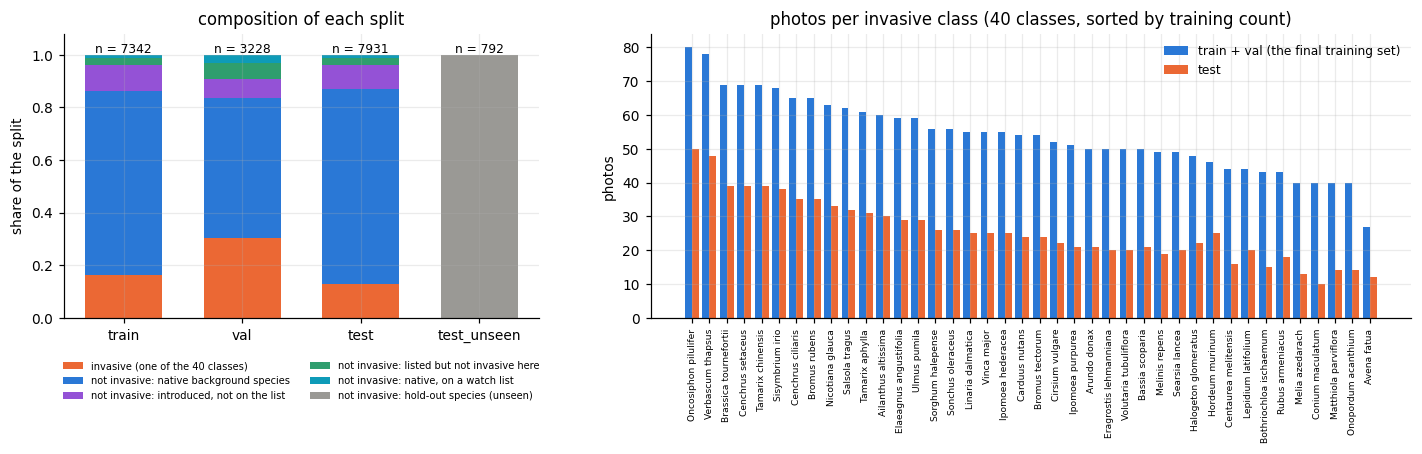

In [6]:
GROUP_ORDER = ["invasive", "native_background", "introduced_unlisted", "listed_not_invasive", "native_listed"]
GROUP_LABELS = {"invasive": "invasive (one of the 40 classes)", "native_background": "not invasive: native background species",
                "introduced_unlisted": "not invasive: introduced, not on the list", "listed_not_invasive": "not invasive: listed but not invasive here",
                "native_listed": "not invasive: native, on a watch list", "holdout_unseen": "not invasive: hold-out species (unseen)"}

rows = []
for name, df in dfs.items():
    inv = df["y"] < N_INVASIVE
    rows.append({"split": name, "photos": len(df), "invasive": int(inv.sum()), "not_invasive": int((~inv).sum()),
                 "invasive_share": float(inv.mean()), "invasive_classes": int(df.loc[inv, "label"].nunique()),
                 "species": int(df["scientific_name"].nunique()), "observers": int(df["observer_id"].nunique()),
                 **{g: int((df["group"] == g).sum()) for g in GROUP_ORDER}})
split_overview = pd.DataFrame(rows).set_index("split")
split_overview.loc["train + val"] = split_overview.loc[["train", "val"]].sum(numeric_only=True)
split_overview.loc["train + val", "invasive_share"] = split_overview.loc["train + val", "invasive"] / split_overview.loc["train + val", "photos"]
split_overview.loc["train + val", "invasive_classes"] = trainval_df.loc[trainval_df["y"] < N_INVASIVE, "label"].nunique()
split_overview.loc["train + val", "species"] = trainval_df["scientific_name"].nunique()
split_overview.loc["train + val", "observers"] = trainval_df["observer_id"].nunique()
split_overview = split_overview.loc[["train", "val", "train + val", "test", "test_unseen"]].astype({c: int for c in split_overview.columns if c != "invasive_share"})
split_overview.to_csv(OUT_DIR / "split_overview.csv")
display(split_overview.style.format({"invasive_share": "{:.3f}"}))

n_unseen_species = unseen_df["scientific_name"].nunique()
print(f"test_unseen: {len(unseen_df)} photos of {n_unseen_species} hold-out species "
      f"({len(unseen_df) / n_unseen_species:.0f} photos per species on average); all labeled {NONE_LABEL}.")

# per-class counts of the 40 invasive classes in train / val / test
class_counts = pd.DataFrame({name: dfs[name].loc[dfs[name]["y"] < N_INVASIVE, "label"].value_counts() for name in ["train", "val", "test"]}
                            ).reindex(INVASIVE_CLASSES).fillna(0).astype(int)
class_counts["train + val"] = class_counts["train"] + class_counts["val"]
class_counts = class_counts.sort_values("train + val", ascending=False)
class_counts.to_csv(OUT_DIR / "class_counts.csv")
print(f"photos per invasive class, train + val: min {class_counts['train + val'].min()}, median {class_counts['train + val'].median():.0f}, "
      f"max {class_counts['train + val'].max()} | test: min {class_counts['test'].min()}, median {class_counts['test'].median():.0f}, max {class_counts['test'].max()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
# left: composition of each split by group (stacked, as shares)
ax = axes[0]
comp = split_overview.loc[["train", "val", "test"], GROUP_ORDER].T
comp["test_unseen"] = 0
comp.loc["holdout_unseen"] = [0, 0, 0, len(unseen_df)]
shares = comp / comp.sum(axis=0)
bottom = np.zeros(shares.shape[1])
for g in shares.index:
    ax.bar(shares.columns, shares.loc[g].values, bottom=bottom, color=GROUP_COLORS[g], label=GROUP_LABELS[g], width=0.65)
    bottom += shares.loc[g].values
for i, n in enumerate(comp.sum(axis=0).values):
    ax.text(i, 1.01, f"n = {int(n)}", ha="center", fontsize=8)
ax.set_ylim(0, 1.08); ax.set_ylabel("share of the split"); ax.set_title("composition of each split")
ax.legend(fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
# right: photos per invasive class, train + val next to test
ax = axes[1]
x = np.arange(N_INVASIVE); w = 0.4
ax.bar(x - w / 2, class_counts["train + val"].values, width=w, color=C_BLUE, label="train + val (the final training set)")
ax.bar(x + w / 2, class_counts["test"].values, width=w, color=C_ORANGE, label="test")
ax.set_xticks(x); ax.set_xticklabels(class_counts.index, rotation=90, fontsize=6)
ax.set_ylabel("photos"); ax.set_title(f"photos per invasive class ({N_INVASIVE} classes, sorted by training count)"); ax.legend(fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(OUT_DIR / "split_overview.png", bbox_inches="tight"); plt.show()

In [8]:
# Check which image files exist
for name, df in dfs.items():
    df["exists"] = df["image_path"].map(lambda p: (DATA_ROOT / p).is_file())
    n_missing = (~df["exists"]).sum()
    if n_missing:
        print(f"{name}: {n_missing} rows without an image file (dropped). Worst classes:\n{df.loc[~df['exists'], 'label'].value_counts().head(8).to_string()}")
    else:
        print(f"{name}: all {len(df)} image files present")
train_df, val_df, test_df, unseen_df = (dfs[s][dfs[s]["exists"]].reset_index(drop=True) for s in SPLITS)
trainval_df = pd.concat([train_df, val_df], ignore_index=True)
assert len(trainval_df) and len(test_df) and len(unseen_df), "no images found under DATA_ROOT; is Drive mounted / are the images downloaded?"

train: all 7342 image files present
val: all 3228 image files present
test: all 7931 image files present
test_unseen: all 792 image files present


### 2c. Image cache

As in the experiment notebooks, every image is decoded once into RAM as uint8: the training images (train + val) resized to the shorter side `presize` and stored ragged, the test and unseen images resized and center-cropped to `image_size`. About 4 GB for the four splits at the design sizes (256 / 224).

In [9]:
class _Decode(Dataset):
    # one-off decode + deterministic resize; wrapped in a DataLoader only to use several worker processes
    def __init__(self, paths, tf):
        self.paths, self.tf = list(paths), tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = ImageOps.exif_transpose(Image.open(DATA_ROOT / self.paths[i])).convert("RGB")
        return T.functional.pil_to_tensor(self.tf(img))                  # uint8, C x H x W


def decode_all(paths, tf, desc, num_workers=2):
    dl = DataLoader(_Decode(paths, tf), batch_size=None, num_workers=num_workers,   # batch_size=None: items stay ragged
                    generator=torch.Generator().manual_seed(0))                     # do not touch the global RNG
    return [t for t in tqdm(dl, total=len(paths), desc=desc, unit="img", leave=False)]


class RaggedUint8:
    """Images of different sizes in ONE flat uint8 tensor plus shapes and offsets. A single allocation is shared copy-on-write
    by the forked DataLoader workers, whereas a Python list of thousands of tensors slowly gets duplicated into every worker."""
    def __init__(self, flat, shapes, offsets):
        self.flat, self.shapes, self.offsets = flat, shapes, offsets

    @classmethod
    def from_list(cls, tensors):
        shapes = torch.tensor([list(t.shape) for t in tensors])
        offsets = torch.cat([torch.zeros(1, dtype=torch.long), shapes.prod(1).cumsum(0)])
        return cls(torch.cat([t.flatten() for t in tensors]), shapes, offsets)

    def __len__(self):
        return len(self.shapes)

    def __getitem__(self, i):
        return self.flat[self.offsets[i]:self.offsets[i + 1]].view(*self.shapes[i].tolist())


_TRAIN_CACHES, _EVAL_CACHES = {}, {}

def train_images_cache(cfg) -> RaggedUint8:
    # train + val images at the configuration's presize; built once per kernel per presize
    key = cfg["presize"]
    if key not in _TRAIN_CACHES:
        t0 = time.time()
        _TRAIN_CACHES[key] = RaggedUint8.from_list(decode_all(trainval_df["image_path"], T.Resize(key), "decoding train + val images", cfg["num_workers"]))
        print(f"image cache: {len(_TRAIN_CACHES[key])} train + val images at presize {key} = {_TRAIN_CACHES[key].flat.numel() / 2**30:.2f} GB ({time.time() - t0:.0f}s)")
    return _TRAIN_CACHES[key]

def eval_images_cache(cfg) -> tuple:
    # (test crops, unseen crops) at the configuration's val_resize / image_size: the deterministic eval transform of every notebook
    key = (cfg["val_resize"], cfg["image_size"])
    if key not in _EVAL_CACHES:
        t0 = time.time(); tf = T.Compose([T.Resize(key[0]), T.CenterCrop(key[1])])
        test_images = torch.stack(decode_all(test_df["image_path"], tf, "decoding test images", cfg.get("num_workers", 2)))
        unseen_images = torch.stack(decode_all(unseen_df["image_path"], tf, "decoding test_unseen images", cfg.get("num_workers", 2)))
        _EVAL_CACHES[key] = (test_images, unseen_images)
        print(f"image cache: {len(test_images)} test + {len(unseen_images)} unseen crops of {key[1]}x{key[1]} = "
              f"{(test_images.numel() + unseen_images.numel()) / 2**30:.2f} GB ({time.time() - t0:.0f}s)")
    return _EVAL_CACHES[key]


# Build the caches now at the sizes the models use, so the time is spent here rather than inside the first training run.
_sizes = {s: (r["hyperparameters"].get("presize"), r["hyperparameters"]["val_resize"], r["hyperparameters"]["image_size"]) for s, r in MODELS.items()}
print("sizes (presize, val_resize, image_size) per series:", _sizes)
for s in FINETUNE_SERIES:
    train_images_cache(MODELS[s]["hyperparameters"])
for s in MODELS:
    eval_images_cache(MODELS[s]["hyperparameters"])

sizes (presize, val_resize, image_size) per series: {'bioclip2': (None, 256, 224), 'finetune': (256, 256, 224)}


decoding train + val images:   0%|          | 0/10570 [00:00<?, ?img/s]

image cache: 10570 train + val images at presize 256 = 2.73 GB (2932s)


decoding test images:   0%|          | 0/7931 [00:00<?, ?img/s]

decoding test_unseen images:   0%|          | 0/792 [00:00<?, ?img/s]

image cache: 7931 test + 792 unseen crops of 224x224 = 1.22 GB (2364s)


## 3. Backbone adapters (copied from the experiment notebooks)

A backbone adapter returns a `BackboneSpec`: an `nn.Module` whose `forward(x)` maps a normalized image batch to the native pooled feature vector, plus the feature dimension and the normalization constants of the checkpoint. The BioCLIP adapters (`open_clip`) are the ones of the BioCLIP 2 notebooks; the frozen model's features are extracted with them.

In [10]:
@dataclass
class BackboneSpec:
    module: nn.Module          # forward(x) -> (B, feat_dim) pooled features
    feat_dim: int
    mean: tuple                # normalization of the checkpoint
    std: tuple
    notes: str = ""

IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


class HFPooledBackbone(nn.Module):
    # Wraps a HF vision model. pooling="cls": .pooler_output (DINOv3: final-normed CLS token).
    # pooling="cls+patchmean": CLS concatenated with the mean of the patch tokens (skips CLS + register tokens).
    def __init__(self, hf_model, pooling="cls", n_prefix_tokens=1):
        super().__init__(); self.m = hf_model; self.pooling = pooling; self.n_prefix = n_prefix_tokens
        assert pooling in ("cls", "cls+patchmean"), pooling
    def forward(self, x):
        out = self.m(pixel_values=x)
        if self.pooling == "cls":
            return out.pooler_output
        return torch.cat([out.pooler_output, out.last_hidden_state[:, self.n_prefix:].mean(1)], dim=1)


def build_plantnet_dinov3_vits(cfg) -> BackboneSpec:
    # PlantNet/plantnet-300k-v2-vits: DINOv3 ViT-S/16 encoder + 1000-way head in model.pth. The encoder architecture is rebuilt
    # from config (ViT-S/16 with 4 register tokens) so the gated facebook/dinov3-* weights are NOT needed; the 1000-class head is discarded.
    from huggingface_hub import snapshot_download
    from transformers import DINOv3ViTConfig, DINOv3ViTModel
    repo = snapshot_download("PlantNet/plantnet-300k-v2-vits", allow_patterns=["model.pth", "plantnet_config.json"])
    pn_cfg = json.load(open(Path(repo) / "plantnet_config.json"))
    ckpt = torch.load(Path(repo) / "model.pth", map_location="cpu", weights_only=True)
    bk = cfg.get("backbone_kwargs", {})
    pooling, drop_path = bk.get("pooling", "cls"), bk.get("drop_path_rate", 0.0)
    encoder = DINOv3ViTModel(DINOv3ViTConfig(hidden_size=384, num_hidden_layers=12, num_attention_heads=6,
                                             intermediate_size=1536, patch_size=16, num_register_tokens=4,
                                             image_size=cfg["image_size"], drop_path_rate=drop_path))
    encoder.load_state_dict(ckpt["encoder"], strict=True)
    feat_dim = pn_cfg["embedding_dim"] * (2 if pooling == "cls+patchmean" else 1)
    return BackboneSpec(HFPooledBackbone(encoder, pooling, n_prefix_tokens=1 + 4), feat_dim, tuple(pn_cfg["image_mean"]),
                        tuple(pn_cfg["image_std"]),
                        notes=f"PlantNet-300K-v2 fine-tuned DINOv3 ViT-S/16; PlantNet mean/std; pooling={pooling}, drop_path={drop_path}")


def build_dinov3_vits16(cfg) -> BackboneSpec:
    # Plain DINOv3 ViT-S/16 (self-supervised, LVD-1689M). Gated: accept the license on HF and `huggingface-cli login`.
    from transformers import AutoModel
    enc = AutoModel.from_pretrained("facebook/dinov3-vits16-pretrain-lvd1689m")
    pooling = cfg.get("backbone_kwargs", {}).get("pooling", "cls")
    feat_dim = enc.config.hidden_size * (2 if pooling == "cls+patchmean" else 1)
    return BackboneSpec(HFPooledBackbone(enc, pooling, 1 + enc.config.num_register_tokens), feat_dim, IMAGENET_MEAN, IMAGENET_STD,
                        notes=f"DINOv3 ViT-S/16, ImageNet mean/std, pooling={pooling}")


class OpenClipVisual(nn.Module):
    # The image tower of an open_clip model. features="projected": the CLIP image embedding that the contrastive loss was
    # trained on (BioCLIP 512-d, BioCLIP 2 768-d); features="pre_proj": the pooled CLS token after ln_post, before the projection.
    def __init__(self, visual, features="projected"):
        super().__init__(); assert features in ("projected", "pre_proj"), features
        self.m = visual
        if features == "pre_proj":
            self.m.proj = None
    def forward(self, x):
        return self.m(x)


def build_open_clip(hf_repo):
    # BioCLIP (imageomics/bioclip: ViT-B/16) and BioCLIP 2 (imageomics/bioclip-2: ViT-L/14) are open_clip checkpoints on the HF hub.
    # The text tower is loaded and discarded: the zero-shot vocabulary embeddings come from best.joblib.
    def _build(cfg) -> BackboneSpec:
        import open_clip
        features = cfg.get("backbone_kwargs", {}).get("features", "projected")
        clip = open_clip.create_model(f"hf-hub:{hf_repo}")
        visual = clip.visual; del clip
        mean = tuple(getattr(visual, "image_mean", None) or open_clip.OPENAI_DATASET_MEAN)
        std = tuple(getattr(visual, "image_std", None) or open_clip.OPENAI_DATASET_STD)
        feat_dim = visual.output_dim if features == "projected" else visual.transformer.width
        return BackboneSpec(OpenClipVisual(visual, features), feat_dim, mean, std,
                            notes=f"{hf_repo} image tower (open_clip), CLIP mean/std, features={features}")
    return _build


BACKBONE_REGISTRY = {
    "dinov3_vits16": build_dinov3_vits16,
    "bioclip2": build_open_clip("imageomics/bioclip-2"),
}
for s, rec in MODELS.items():
    assert rec["backbone"] in BACKBONE_REGISTRY, f"{s}: backbone {rec['backbone']!r} has no adapter; registered: {list(BACKBONE_REGISTRY)}"
print("registered backbones:", list(BACKBONE_REGISTRY))

registered backbones: ['dinov3_vits16', 'bioclip2']


### 3b. Classifier: backbone -> pooled features -> Dropout -> Linear
Head initialized with Xavier-uniform weights and zero biases, as in the experiment notebooks.

In [11]:
class InvasiveClassifier(nn.Module):
    def __init__(self, spec: BackboneSpec, n_classes: int, dropout: float):
        super().__init__()
        self.backbone = spec.module
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(spec.feat_dim, n_classes)
        nn.init.xavier_uniform_(self.head.weight); nn.init.zeros_(self.head.bias)

    def forward(self, x):
        return self.head(self.dropout(self.backbone(x)))

    def set_backbone_frozen(self, frozen: bool):
        for p in self.backbone.parameters():
            p.requires_grad_(not frozen)


def build_model(cfg):
    spec = BACKBONE_REGISTRY[cfg["model_name"]](cfg)
    model = InvasiveClassifier(spec, N_INVASIVE, cfg["dropout"]).to(DEVICE)
    n_bb = sum(p.numel() for p in model.backbone.parameters()); n_head = sum(p.numel() for p in model.head.parameters())
    print(f"{cfg['model_name']}: backbone {n_bb/1e6:.1f}M params, head {n_head/1e3:.1f}K params, feat_dim {spec.feat_dim} | {spec.notes}")
    return model, spec

## 4. Training dataset and transforms (copied)

Train: `RandomResizedCrop(image_size, scale=rrc_scale)` from the image at `presize`, horizontal flip, rotation, color jitter, normalize with the backbone's mean/std, per sample in the loader workers. There is no validation loader: the test and unseen crops are scored directly from the cache in Section 9, normalized on the device.

In [12]:
def make_train_transform(cfg, spec: BackboneSpec):
    cj = cfg["color_jitter"]
    return v2.Compose([
        v2.RandomResizedCrop(cfg["image_size"], scale=tuple(cfg["rrc_scale"]), antialias=True),   # from the presize image
        v2.RandomHorizontalFlip(p=cfg["hflip_p"]),
        v2.RandomRotation(cfg["rotation_deg"]),
        v2.ColorJitter(**cj),
        v2.ToDtype(torch.float32, scale=True), v2.Normalize(spec.mean, spec.std)])


class InatImages(Dataset):
    def __init__(self, images, df: pd.DataFrame, transform, n_invasive: int):
        self.images = images                     # RaggedUint8, indexed like df
        self.y = df["y"].to_numpy(); self.transform = transform; self.n = n_invasive
        assert len(images) == len(df), "image cache does not match the dataframe"

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.transform(self.images[i])
        target = torch.zeros(self.n, dtype=torch.float32)
        if self.y[i] < self.n:
            target[self.y[i]] = 1.0                     # not_invasive stays all-zero
        return x, target, int(self.y[i])


def make_train_loader(cfg, spec):
    g = torch.Generator(); g.manual_seed(cfg["seed"])
    kw = dict(num_workers=cfg["num_workers"], pin_memory=DEVICE.type == "cuda", persistent_workers=cfg["num_workers"] > 0)
    return DataLoader(InatImages(train_images_cache(cfg), trainval_df, make_train_transform(cfg, spec), N_INVASIVE),
                      batch_size=cfg["batch_size"], shuffle=True, drop_last=True, generator=g, **kw)


def show_batch(dl, spec, n=12, title="training batch (augmented)"):
    x, _, y = next(iter(dl))
    mean, std = torch.tensor(spec.mean).view(3, 1, 1), torch.tensor(spec.std).view(3, 1, 1)
    cols = 6; rows = math.ceil(min(n, len(x)) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.4))
    for ax in axes.flat: ax.axis("off")
    for ax, xi, yi in zip(axes.flat, x[:n], y[:n]):
        ax.imshow((xi * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
        ax.set_title(ALL_LABELS[yi].replace(" ", "\n"), fontsize=7)
    fig.suptitle(title); fig.tight_layout(); plt.show()

## 5. Metrics and plots (copied)

Inputs: `probs` of shape `(N, N_INVASIVE)` and `y` in `0..N_INVASIVE`. `compute_metrics` is the experiment notebooks' function; here it is always called with a **fixed threshold** (the validation one), so no sweep is done on the test set.

| metric | definition |
|---|---|
| `macro_ap_invasive` | mean over the invasive classes of average precision (one-vs-rest, threshold-free) |
| `top1_recall_invasive`, `top3_recall_invasive` | among rows whose true label is invasive: is the true class the top-1 / within the top-3 ranked logits (threshold-free) |
| `macro_f1_invasive` | **primary validation metric**: per-class F1 averaged over the invasive classes only |
| `top1_acc_all` | **primary KPI**: accuracy of the 41-way prediction over all rows |
| `bin_*_invasive` | binary "invasive vs not" with score `max prob` and threshold `t` |
| `noninv_*` | the same binary problem seen from the `not_invasive` side (score `1 - max prob`) |
| `per_class_f1`, `per_class_ap`, `confusion_matrix` | arrays for the plots and for `metrics_test.json` |

In [13]:
def predict_not_invasive(probs: np.ndarray, t: float) -> np.ndarray:
    # Species when the strongest invasive probability clears t, otherwise not_invasive.
    pred = probs.argmax(1)
    pred[probs.max(1) < t] = N_INVASIVE
    return pred


def macro_f1_invasive(y: np.ndarray, pred: np.ndarray) -> float:
    f1 = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y))
    return float(f1[:N_INVASIVE].mean())


def tune_threshold(probs, y, grid):
    sweep = pd.DataFrame({"threshold": grid})
    sweep["macro_f1_invasive"] = [macro_f1_invasive(y, predict_not_invasive(probs, t)) for t in grid]
    sweep["top1_acc_all"] = [float((predict_not_invasive(probs, t) == y).mean()) for t in grid]
    best = sweep.loc[sweep["macro_f1_invasive"].idxmax()]
    return float(best["threshold"]), sweep


def compute_metrics(probs: np.ndarray, y: np.ndarray, threshold: float | None, grid=None) -> dict:
    probs = np.asarray(probs, dtype=np.float64); y = np.asarray(y)
    is_inv = y < N_INVASIVE
    onehot = np.eye(N_INVASIVE + 1)[y][:, :N_INVASIVE]              # (N, N_INVASIVE) binary targets

    m = {}
    per_class_ap = np.array([average_precision_score(onehot[:, c], probs[:, c]) if onehot[:, c].any() else np.nan
                             for c in range(N_INVASIVE)])
    m["macro_ap_invasive"] = float(np.nanmean(per_class_ap))
    if is_inv.any():
        rank = (-probs[is_inv]).argsort(1)
        m["top1_recall_invasive"] = float((rank[:, 0] == y[is_inv]).mean())
        m["top3_recall_invasive"] = float((rank[:, :3] == y[is_inv, None]).any(1).mean())
    sweep = None
    if threshold is None:
        threshold, sweep = tune_threshold(probs, y, grid)
    m["threshold"] = float(threshold)
    pred = predict_not_invasive(probs, threshold)
    f1_per_class = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y)).numpy()
    m["macro_f1_invasive"] = float(f1_per_class[:N_INVASIVE].mean())
    m["macro_f1_all41"] = float(f1_per_class.mean())
    m["top1_acc_all"] = float(MulticlassAccuracy(num_classes=N_INVASIVE + 1, average="micro")(torch.as_tensor(pred), torch.as_tensor(y)))
    score_inv = probs.max(1); pred_inv = pred < N_INVASIVE
    m["bin_precision_invasive"] = precision_score(is_inv, pred_inv, zero_division=0)
    m["bin_recall_invasive"] = recall_score(is_inv, pred_inv, zero_division=0)
    m["bin_f1_invasive"] = f1_score(is_inv, pred_inv, zero_division=0)
    m["bin_ap_invasive"] = average_precision_score(is_inv, score_inv)
    m["bin_auroc_invasive"] = roc_auc_score(is_inv, score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    m["noninv_precision"] = precision_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_recall"] = recall_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_auroc"] = roc_auc_score(~is_inv, 1 - score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    m["per_class_f1"] = f1_per_class.tolist()
    m["per_class_ap"] = per_class_ap.tolist()
    m["confusion_matrix"] = MulticlassConfusionMatrix(num_classes=N_INVASIVE + 1)(torch.as_tensor(pred), torch.as_tensor(y)).numpy().tolist()
    m["_sweep"] = sweep; m["_pred"] = pred
    return m


def scalars(m: dict) -> dict:
    return {k: float(m[k]) for k in SCALAR_METRICS if k in m}

In [14]:
def plot_training_curves(hist: pd.DataFrame, out_dir: Path, title=""):
    # No validation curve: the final models train on train + val. Loss, gradient norm and learning rates per epoch.
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    ax = axes[0]; ax.plot(hist["epoch"], hist["train_loss"], color=C_BLUE, lw=2)
    ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.set_title("training loss")
    ax = axes[1]; ax.plot(hist["epoch"], hist["grad_norm_mean"], color=C_BLUE, lw=2, label="mean over the epoch")
    ax.plot(hist["epoch"], hist["grad_norm_max"], color=C_GRAY, lw=1.5, label="max over the epoch")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title("gradient norm (before clipping)"); ax.legend(fontsize=7)
    ax = axes[2]; ax.plot(hist["epoch"], hist["lr_head"], color=C_ORANGE, lw=2, label="head LR")
    ax.plot(hist["epoch"], hist["lr_backbone"], color=C_BLUE, lw=2, label="backbone LR")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title("learning rate"); ax.legend(fontsize=7)
    for a in axes:
        if hist.attrs.get("frozen_epochs"):
            a.axvline(hist.attrs["frozen_epochs"] + 0.5, color=C_GRAY, ls="--", lw=1)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "training_curves.png"); plt.show()


def plot_pr_roc(probs, y, m: dict, out_dir: Path, title=""):
    is_inv = y < N_INVASIVE; score = probs.max(1); t = m["threshold"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    p, r, th = precision_recall_curve(is_inv, score)
    ax = axes[0]; ax.plot(r, p, color=C_BLUE, lw=2)
    ax.scatter([m["bin_recall_invasive"]], [m["bin_precision_invasive"]], color=C_ORANGE, s=40, zorder=3, label=f"operating point, t={t:.2f}")
    ax.axhline(is_inv.mean(), color=C_GRAY, ls=":", lw=1, label=f"prevalence {is_inv.mean():.2f}")
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"binary invasiveness: AP = {m['bin_ap_invasive']:.3f}"); ax.legend(fontsize=7, loc="lower left")
    ax = axes[1]
    for c in range(N_INVASIVE):
        yc = (y == c)
        if yc.any():
            pc, rc, _ = precision_recall_curve(yc, probs[:, c]); ax.plot(rc, pc, color=C_BLUE, alpha=0.25, lw=1)
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"per-class PR, {N_INVASIVE} invasive classes: macro-AP = {m['macro_ap_invasive']:.3f}")
    ax = axes[2]
    if 0 < is_inv.sum() < len(y):
        fpr, tpr, _ = roc_curve(is_inv, score); ax.plot(fpr, tpr, color=C_BLUE, lw=2)
        fpr_t = float((~is_inv & (score >= t)).sum() / max((~is_inv).sum(), 1))
        ax.scatter([fpr_t], [m["bin_recall_invasive"]], color=C_ORANGE, s=40, zorder=3)
    ax.plot([0, 1], [0, 1], color=C_GRAY, ls=":", lw=1)
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title(f"binary invasiveness ROC: AUROC = {m['bin_auroc_invasive']:.3f}")
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "pr_roc.png"); plt.show()


def plot_confusion(m: dict, out_dir: Path, title="", normalize=True):
    cm = np.array(m["confusion_matrix"], dtype=float)
    if normalize:
        cm = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(len(ALL_LABELS))); ax.set_yticks(range(len(ALL_LABELS)))
    ax.set_xticklabels(ALL_LABELS, rotation=90, fontsize=6); ax.set_yticklabels(ALL_LABELS, fontsize=6)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(title or "confusion matrix")
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); fig.tight_layout(); fig.savefig(out_dir / "confusion_matrix.png"); plt.show()


def plot_per_class_f1(m: dict, out_dir: Path, support: pd.Series, title=""):
    f1 = pd.Series(m["per_class_f1"][:N_INVASIVE], index=INVASIVE_CLASSES).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.22 * N_INVASIVE + 1.5))
    ax.barh(f1.index, f1.values, color=C_BLUE, height=0.7)
    for i, (name, v) in enumerate(f1.items()):
        ax.text(min(v + 0.01, 0.9), i, f"n={int(support.get(name, 0))}", va="center", fontsize=6, color="#52514e")
    ax.set_xlim(0, 1); ax.set_xlabel("F1-score"); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(title or f"per-class F1; macro-F1 (invasive species) = {m['macro_f1_invasive']:.3f}")
    fig.tight_layout(); fig.savefig(out_dir / "per_class_f1.png"); plt.show()

## 6. Training loop without a validation set

The experiment notebooks' loop, minus the per-epoch validation: `frozen_epochs` with the backbone frozen (constant `frozen_head_lr`, AdamW on the head only), then `full_epochs` of full fine-tuning with AdamW (`weight_decay`, not on 1-d parameters and tokens when `weight_decay_exclude_1d`), per-group peak LRs (`backbone_lr`, `head_lr`, scaled per block by `layer_decay` when set) and a 1-cycle cosine schedule (`pct_start`). Mixed precision, gradient clipping at `grad_clip_norm`, stop on a non-finite loss. **The weights after the last epoch are kept** (`final.pt`): there is no held-out set to select an epoch on, and the 1-cycle schedule anneals the learning rate to zero so the last epoch is the natural end point. For comparison, the epoch the validation run selected is printed next to the schedule.

In [15]:
def make_loss(cfg):
    pw = None if cfg["bce_pos_weight"] is None else torch.full((N_INVASIVE,), float(cfg["bce_pos_weight"]), device=DEVICE)
    return nn.BCEWithLogitsLoss(pos_weight=pw)


def apply_mixup_and_smoothing(x, target, cfg):
    eps = cfg["label_smoothing"]
    if eps > 0:
        target = target * (1 - eps) + 0.5 * eps
    if cfg["mixup_alpha"] > 0:
        lam = float(np.random.beta(cfg["mixup_alpha"], cfg["mixup_alpha"]))
        perm = torch.randperm(x.size(0), device=x.device)
        x = lam * x + (1 - lam) * x[perm]; target = lam * target + (1 - lam) * target[perm]
    return x, target


def train_one_epoch(model, dl, optimizer, scheduler, scaler, loss_fn, cfg, frozen: bool, desc: str = ""):
    model.train()
    if frozen:
        model.backbone.eval()                  # frozen stage: backbone statistics untouched (matters for BN backbones)
    use_amp = cfg["amp"] and DEVICE.type == "cuda"
    losses, gnorms = [], []
    n_batches = len(dl) if not cfg["max_batches_per_epoch"] else min(len(dl), cfg["max_batches_per_epoch"])
    bar = tqdm(dl, total=n_batches, desc=desc, leave=False, unit="batch")
    for b, (x, target, _) in enumerate(bar):
        if cfg["max_batches_per_epoch"] and b >= cfg["max_batches_per_epoch"]:
            break
        x, target = x.to(DEVICE, non_blocking=True), target.to(DEVICE, non_blocking=True)
        x, target = apply_mixup_and_smoothing(x, target, cfg)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
            logits = model(x)
        loss = loss_fn(logits.float(), target)
        if not torch.isfinite(loss):
            raise RuntimeError(f"non-finite loss at batch {b}: {loss.item()}")
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        gnorm = torch.nn.utils.clip_grad_norm_([p for g in optimizer.param_groups for p in g["params"]], cfg["grad_clip_norm"])
        scaler.step(optimizer); scaler.update()
        if scheduler is not None:
            scheduler.step()
        losses.append(loss.item()); gnorms.append(float(gnorm))
        if b % 10 == 0 or b == n_batches - 1:
            bar.set_postfix(loss=f"{np.mean(losses[-10:]):.3f}", gnorm=f"{gnorms[-1]:.2f}",
                            lr_head=f"{optimizer.param_groups[0]['lr']:.1e}", refresh=False)
    bar.close()
    return float(np.mean(losses)), float(np.mean(gnorms)), float(np.max(gnorms))


_LAYER_RE = re.compile(r"(?:^|\.)(?:layers?|blocks|resblocks)\.(\d+)\.")   # HF: layer.N | timm: blocks.N | open_clip: resblocks.N

def backbone_layer_id(name: str, n_layers: int) -> int:
    # 0 = embeddings / tokens, 1..n_layers = transformer blocks, n_layers + 1 = everything after (final norm, pooler).
    m = _LAYER_RE.search(name)
    if m:
        return int(m.group(1)) + 1
    if any(k in name for k in ("embed", "token", "conv1", "ln_pre")):
        return 0
    return n_layers + 1


def no_weight_decay(name: str, p: torch.Tensor) -> bool:
    return p.ndim <= 1 or name.endswith(".bias") or any(k in name for k in ("token", "pos_embed", "positional_embedding", "latent"))


def param_groups(model, cfg, frozen_stage=False):
    wd, excl = cfg["weight_decay"], cfg["weight_decay_exclude_1d"]
    groups = {}
    def add(key, p, lr, decay, name):
        g = groups.setdefault(key, {"params": [], "lr": lr, "weight_decay": wd if decay else 0.0, "name": name})
        g["params"].append(p)
    head_lr = cfg["frozen_head_lr"] if frozen_stage else cfg["head_lr"]
    for n, p in model.head.named_parameters():
        decay = not (excl and no_weight_decay(n, p))
        add(("head", decay), p, head_lr, decay, "head")
    if not frozen_stage:
        names = [n for n, _ in model.backbone.named_parameters()]
        ids = [int(m.group(1)) for n in names for m in [_LAYER_RE.search(n)] if m]
        n_layers = (max(ids) + 1) if ids else 0
        for n, p in model.backbone.named_parameters():
            lid = backbone_layer_id(n, n_layers)
            scale = (cfg["layer_decay"] ** (n_layers + 1 - lid)) if cfg["layer_decay"] else 1.0
            decay = not (excl and no_weight_decay(n, p))
            add(("backbone", lid, decay), p, cfg["backbone_lr"] * scale, decay, f"backbone_l{lid}")
    return list(groups.values())


def describe_param_groups(groups):
    rows = [{"group": g["name"], "lr": g["lr"], "weight_decay": g["weight_decay"], "n_params": sum(p.numel() for p in g["params"])} for g in groups]
    return pd.DataFrame(rows).groupby(["group", "lr", "weight_decay"], as_index=False)["n_params"].sum().sort_values(["group", "lr"])


def train_final(cfg: dict, out_dir: Path, title="", show_plots=True, show_batch_preview=True):
    # Trains cfg on train + val for the full schedule; writes config.json, history.csv, final.pt and the curves; returns (model, spec, summary).
    seed_everything(cfg["seed"])
    model, spec = build_model(cfg)
    train_dl = make_train_loader(cfg, spec)
    if show_batch_preview:
        rng = (torch.get_rng_state(), np.random.get_state(), random.getstate())
        show_batch(train_dl, spec, title=f"{title}: training batch (augmented)")
        torch.set_rng_state(rng[0]); np.random.set_state(rng[1]); random.setstate(rng[2])
        train_dl = make_train_loader(cfg, spec)
    loss_fn = make_loss(cfg)
    use_scaler = cfg["amp"] and DEVICE.type == "cuda" and AMP_DTYPE == torch.float16
    scaler = torch.amp.GradScaler(enabled=use_scaler)
    history = []
    steps_per_epoch = len(train_dl) if not cfg["max_batches_per_epoch"] else min(len(train_dl), cfg["max_batches_per_epoch"])
    n_epochs_total = cfg["frozen_epochs"] + cfg["full_epochs"]
    print(f"{n_epochs_total} epochs ({cfg['frozen_epochs']} frozen + {cfg['full_epochs']} full) x {steps_per_epoch} batches of "
          f"{cfg['batch_size']} on {len(train_dl.dataset)} train + val images")
    t_start = time.time()

    def eta(stage):
        done = [r["seconds"] for r in history if r["stage"] == stage]
        n_stage = cfg["frozen_epochs"] if stage == "frozen" else cfg["full_epochs"]
        left = (n_stage - len(done)) * float(np.mean(done))
        tail = " + full stage" if stage == "frozen" and cfg["full_epochs"] else ""
        return f"elapsed {(time.time() - t_start) / 60:.1f}m, ~{left / 60:.1f}m left in {stage} stage{tail}"

    def log(epoch, stage, train_loss, gnorm_mean, gnorm_max, optimizer, t0):
        lr_bb = max([g["lr"] for g in optimizer.param_groups if g["name"].startswith("backbone")], default=0.0)
        lr_head = max(g["lr"] for g in optimizer.param_groups if g["name"] == "head")
        history.append({"epoch": epoch, "stage": stage, "train_loss": train_loss, "grad_norm_mean": gnorm_mean, "grad_norm_max": gnorm_max,
                        "lr_backbone": lr_bb, "lr_head": lr_head, "seconds": time.time() - t0})
        print(f"ep {epoch:>2}/{n_epochs_total} [{stage:<6}] loss {train_loss:.4f} | gnorm {gnorm_mean:.2f} | {history[-1]['seconds']:.0f}s | {eta(stage)}")
        pd.DataFrame(history).to_csv(out_dir / "history.csv", index=False)

    epoch = 0
    if cfg["frozen_epochs"] > 0:
        model.set_backbone_frozen(True)
        opt = torch.optim.AdamW(param_groups(model, cfg, frozen_stage=True))
        for _ in range(cfg["frozen_epochs"]):
            epoch += 1; t0 = time.time()
            tl, gm, gx = train_one_epoch(model, train_dl, opt, None, scaler, loss_fn, cfg, frozen=True, desc=f"epoch {epoch}/{n_epochs_total} (frozen)")
            log(epoch, "frozen", tl, gm, gx, opt, t0)
    if cfg["full_epochs"] > 0:
        model.set_backbone_frozen(False)
        groups = param_groups(model, cfg)
        if show_plots:
            display(describe_param_groups(groups))
        opt = torch.optim.AdamW(groups)
        total_steps = cfg["full_epochs"] * steps_per_epoch
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g["lr"] for g in groups], total_steps=total_steps,
                                                    pct_start=max(cfg["pct_start"], 2 / total_steps),   # at least 2 warm-up steps
                                                    anneal_strategy="cos")
        for _ in range(cfg["full_epochs"]):
            epoch += 1; t0 = time.time()
            tl, gm, gx = train_one_epoch(model, train_dl, opt, sched, scaler, loss_fn, cfg, frozen=False, desc=f"epoch {epoch}/{n_epochs_total} (full)")
            log(epoch, "full", tl, gm, gx, opt, t0)

    hist = pd.DataFrame(history); hist.attrs["frozen_epochs"] = cfg["frozen_epochs"]
    summary = {"epochs": epoch, "frozen_epochs": cfg["frozen_epochs"], "full_epochs": cfg["full_epochs"], "n_train_images": len(train_dl.dataset),
               "train_minutes": float(hist["seconds"].sum() / 60), "final_train_loss": float(hist["train_loss"].iloc[-1]),
               "trained_at": datetime.datetime.now().isoformat(timespec="seconds"), "device": DEVICE_NAME}
    torch.save({"state_dict": model.state_dict(), "epoch": epoch, "threshold": cfg["threshold"], "config": cfg, "summary": summary}, out_dir / "final.pt")
    print(f"done: {epoch} epochs in {summary['train_minutes']:.1f} min, final training loss {summary['final_train_loss']:.4f} -> {out_dir / 'final.pt'}")
    if show_plots:
        plot_training_curves(hist, out_dir, title)
    return model, spec, summary

## 7. Train the fine-tuned model on train + val

The fine-tuned model is trained with the `hyperparameters` recorded in `final_models.json` (the complete `config.json` of the chosen iteration) for its full schedule; only the bookkeeping fields change. The threshold is the one that run tuned on validation. A model whose `final.pt` already exists in `final_test/<series>/` is loaded instead of retrained unless `RETRAIN = True`.

===== DINOv3 ViT-S/16 (fine-tuned) on train + val: dinov3_vits16/04_pool_cls_patchmean
changes vs the fine-tune baseline: {'backbone_kwargs': {'pooling': 'cls+patchmean', 'drop_path_rate': 0.0}, 'frozen_epochs': 8} | schedule 8 + 20 epochs (the validation run kept epoch 21 of 28) | threshold from val 0.14


config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

dinov3_vits16: backbone 21.6M params, head 30.8K params, feat_dim 768 | DINOv3 ViT-S/16, ImageNet mean/std, pooling=cls+patchmean


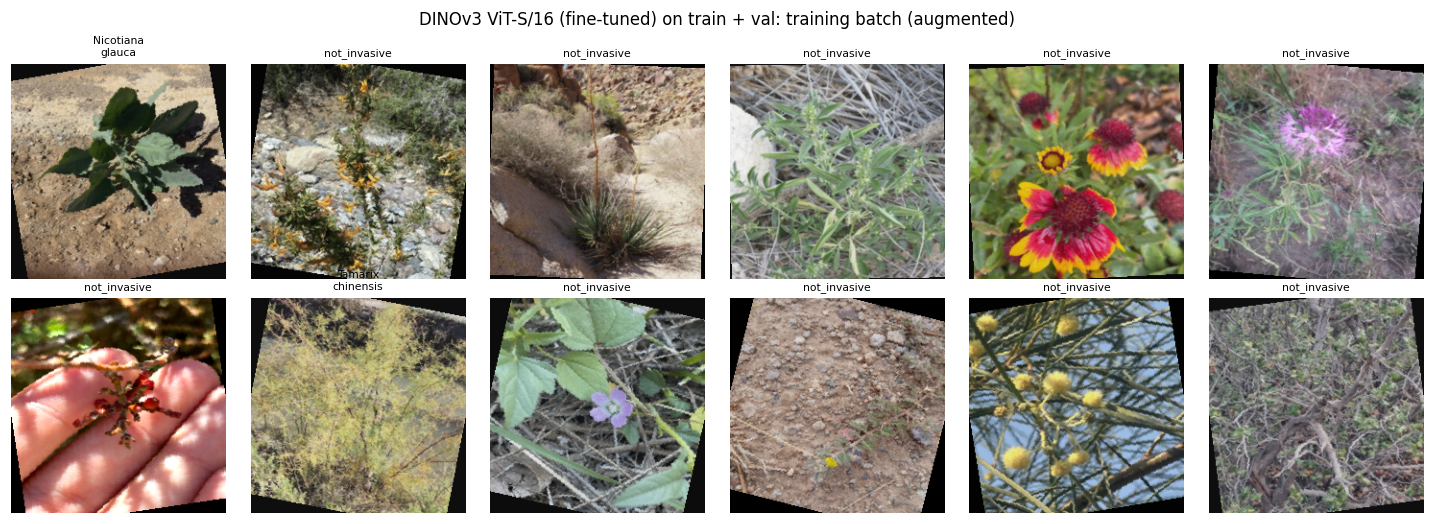

28 epochs (8 frozen + 20 full) x 165 batches of 64 on 10570 train + val images


epoch 1/28 (frozen):   0%|          | 0/165 [00:00<?, ?batch/s]

ep  1/28 [frozen] loss 0.0839 | gnorm 0.06 | 117s | elapsed 2.0m, ~13.7m left in frozen stage + full stage


epoch 2/28 (frozen):   0%|          | 0/165 [00:00<?, ?batch/s]

ep  2/28 [frozen] loss 0.0283 | gnorm 0.02 | 113s | elapsed 3.8m, ~11.5m left in frozen stage + full stage


epoch 3/28 (frozen):   0%|          | 0/165 [00:00<?, ?batch/s]

... (48 outputs left out)

epoch 27/28 (full):   0%|          | 0/165 [00:00<?, ?batch/s]

ep 27/28 [full  ] loss 0.0019 | gnorm 0.06 | 159s | elapsed 65.7m, ~2.7m left in full stage


epoch 28/28 (full):   0%|          | 0/165 [00:00<?, ?batch/s]

ep 28/28 [full  ] loss 0.0019 | gnorm 0.06 | 160s | elapsed 68.4m, ~0.0m left in full stage
done: 28 epochs in 68.4 min, final training loss 0.0019 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/final_test/finetune/final.pt


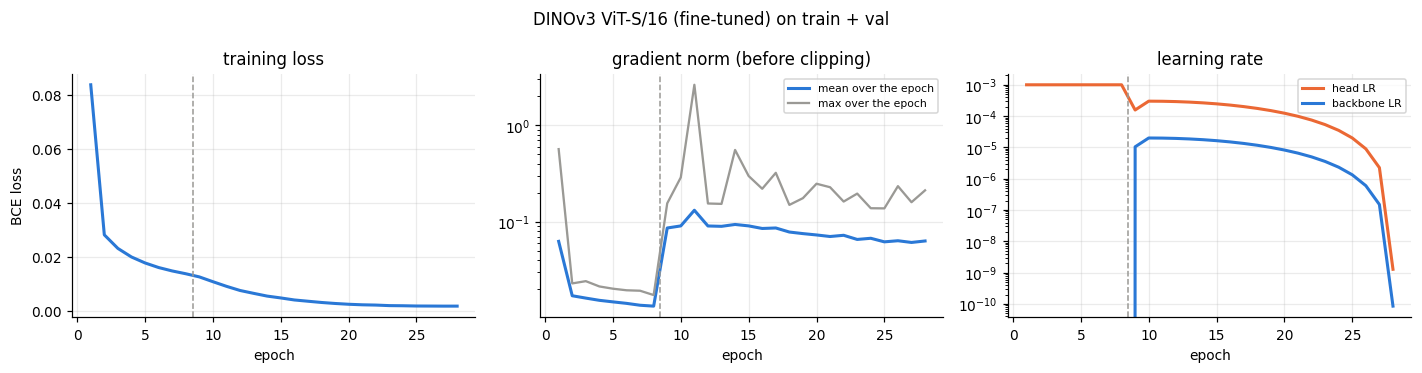

In [16]:
TRAINED = {}          # series -> {"model", "spec", "cfg", "summary"}

def final_config(series: str) -> dict:
    rec = MODELS[series]
    cfg = copy.deepcopy(rec["hyperparameters"])
    cfg.update({"model_name": rec["backbone"], "iteration": f"final_{series}", "trained_on": "train+val", "source_run": rec["candidate"],
                "threshold": float(rec["threshold_val"]), "overrides": {}, "built_on_accepted": cfg.get("built_on_accepted", [])})
    return cfg


def val_run_epochs(series: str) -> str:
    f = SEL_DIR / f"final_{series}_val_metrics.json"
    if f.exists():
        m = json.load(open(f)); return f"the validation run kept epoch {m.get('best_epoch')} of {m.get('epochs')}"
    return "validation run's best epoch unknown"


for s in FINETUNE_SERIES:
    rec = MODELS[s]; out_dir = OUT_DIR / s; out_dir.mkdir(parents=True, exist_ok=True)
    cfg = final_config(s)
    title = f"{MODEL_NAMES[s]} on train + val"
    print(f"===== {title}: {rec['candidate']}\nchanges vs the fine-tune baseline: {rec.get('changes_vs_finetune_baseline') or 'none'} | "
          f"schedule {cfg['frozen_epochs']} + {cfg['full_epochs']} epochs ({val_run_epochs(s)}) | threshold from val {cfg['threshold']:.2f}")
    json.dump(cfg, open(out_dir / "config.json", "w"), indent=1, default=str)
    if (out_dir / "final.pt").exists() and not RETRAIN:
        ckpt = torch.load(out_dir / "final.pt", map_location=DEVICE, weights_only=False)
        model, spec = build_model(cfg); model.load_state_dict(ckpt["state_dict"]); model.eval()
        print(f"loaded existing {out_dir / 'final.pt'} (trained {ckpt['summary']['trained_at'][:16]}, {ckpt['summary']['train_minutes']:.1f} min); "
              "set RETRAIN = True to train again")
        TRAINED[s] = {"model": model, "spec": spec, "cfg": cfg, "summary": ckpt["summary"]}
    else:
        model, spec, summary = train_final(cfg, out_dir, title)
        TRAINED[s] = {"model": model, "spec": spec, "cfg": cfg, "summary": summary}
    model.to("cpu"); torch.cuda.empty_cache()        # park the model in RAM until Section 10 scores it

## 8. BioCLIP 2 one-shot predictions

One-shot predictions from the chosen BioCLIP 2 model. `weights_file` is the `best.joblib` the BioCLIP 2 notebook wrote: the image tower is `BACKBONE_REGISTRY[backbone]` (projected, L2-normalized features), and the file holds what the method needs on top of the features: the vocabulary text embeddings with their class mapping and the logit scale for zero-shot, the training-photo index for kNN, the standardizer and the one-vs-rest classifier for a logistic-regression probe, plus the threshold tuned on validation.

In [18]:
class FrozenMethod:
    # Probabilities over the 40 invasive classes from L2-normalized backbone features, for the methods of the BioCLIP 2 notebooks.
    def __init__(self, art: dict):
        self.art = art; cfg = art["config"]
        self.method = cfg.get("method", "logreg" if "clf" in art else None)
        assert self.method in ("zero_shot", "knn", "knn+zero_shot", "logreg"), f"unknown frozen method {self.method!r}"
        self.threshold = float(art["threshold"])
        if "zero_shot" in self.method:
            self.txt = torch.tensor(np.asarray(art["text_embeddings"], dtype=np.float32), device=DEVICE)     # (V, d), unit norm
            v2l = np.asarray(art["vocab_to_label"]).astype(int)
            M = np.zeros((len(v2l), N_INVASIVE), np.float32); inv = np.flatnonzero(v2l < N_INVASIVE); M[inv, v2l[inv]] = 1
            self.M = torch.tensor(M, device=DEVICE); self.logit_scale = float(art["logit_scale"])
        if "knn" in self.method:
            self.Ftr = torch.tensor(np.asarray(art["train_features"], dtype=np.float32), device=DEVICE)
            self.ytr = torch.tensor(np.asarray(art["train_y"]).astype(int), device=DEVICE)
            self.k, self.tau = int(art["k"]), float(art["tau"])
        if self.method == "knn+zero_shot":
            self.w_knn = float(cfg["w_knn"])

    def describe(self) -> str:
        if self.method == "zero_shot":
            return f"zero-shot over {len(self.txt)} vocabulary names (logit scale {self.logit_scale:.0f})"
        if self.method == "knn":
            return f"kNN, k={self.k}, tau={self.tau}, over {len(self.Ftr)} training photos"
        if self.method == "knn+zero_shot":
            return f"{self.w_knn} kNN (k={self.k}) + {1 - self.w_knn} zero-shot over {len(self.txt)} names"
        return f"logistic regression probe (C={self.art.get('C')})"

    def _zs(self, Fq):
        return torch.softmax(self.logit_scale * Fq @ self.txt.T, dim=1) @ self.M

    def _knn(self, Fq):
        s, i = (Fq @ self.Ftr.T).topk(self.k, dim=1)
        w = torch.softmax(s / self.tau, dim=1); lab = self.ytr[i]
        p = torch.zeros(len(Fq), N_INVASIVE + 1, device=Fq.device).scatter_add_(1, lab, w)
        return p[:, :N_INVASIVE]

    def __call__(self, feats: torch.Tensor) -> torch.Tensor:
        Fq = F.normalize(feats.float(), dim=-1)
        if self.method == "zero_shot":
            return self._zs(Fq)
        if self.method == "knn":
            return self._knn(Fq)
        if self.method == "knn+zero_shot":
            return self.w_knn * self._knn(Fq) + (1 - self.w_knn) * self._zs(Fq)
        X = feats.float().cpu().numpy()                       # the probe standardizes the raw (not unit-normalized) features
        X = self.art["scaler"].transform(X) if self.art.get("scaler") is not None else X
        return torch.tensor(self.art["clf"].predict_proba(X), dtype=torch.float32, device=feats.device)


FROZEN = {}           # series -> {"spec", "method", "cfg"}
for s in FROZEN_SERIES:
    rec = MODELS[s]; out_dir = OUT_DIR / s; out_dir.mkdir(parents=True, exist_ok=True)
    wf = run_path(rec["weights_file"])
    assert wf.exists(), f"{s}: weights file not found: {wf}"
    art = joblib.load(wf)
    assert art["backbone"] == rec["backbone"], f"{s}: best.joblib was built on {art['backbone']}, final_models.json says {rec['backbone']}"
    assert list(art["labels"]) == ALL_LABELS, f"{s}: label order in best.joblib differs from this dataset's"
    cfg = {**copy.deepcopy(art["config"]), "model_name": rec["backbone"], "source_run": rec["candidate"], "threshold": float(art["threshold"])}
    if abs(cfg["threshold"] - rec["threshold_val"]) > 1e-6:
        print(f"{s}: best.joblib threshold {cfg['threshold']:.3f} differs from final_models.json threshold_val {rec['threshold_val']:.3f}; using best.joblib's")
    method = FrozenMethod(art)
    spec = BACKBONE_REGISTRY[rec["backbone"]](cfg)
    spec.module.to("cpu").eval()
    FROZEN[s] = {"spec": spec, "method": method, "cfg": cfg}
    json.dump(cfg, open(out_dir / "config.json", "w"), indent=1, default=str)
    print(f"{MODEL_NAMES[s]}: {rec['candidate']} -> {method.describe()}; threshold {method.threshold:.2f}; features: {spec.notes}")
    del art

BioCLIP 2 ViT-L/14 (zero-shot): bioclip2_zeroshot_full/00_baseline -> zero-shot over 4573 vocabulary names (logit scale 100); threshold 0.06; features: imageomics/bioclip-2 image tower (open_clip), CLIP mean/std, features=projected


## 9. One scorer per model

A scorer maps a batch of cached uint8 crops to the `(B, 40)` probabilities, doing on the device everything the model needs at inference: normalization with the backbone's mean/std, the forward pass, the mirror-image pass when the configuration uses TTA (both do), and the sigmoid (fine-tuned) or the zero-shot / kNN step (frozen). The timed evaluation of Section 10 treats both the same way.

In [19]:
class Scorer:
    def __init__(self, series: str, module: nn.Module, spec: BackboneSpec, cfg: dict, head=None):
        # head: None for a fine-tuned classifier (module is the InvasiveClassifier -> sigmoid of its logits);
        #       a FrozenMethod for a frozen backbone (module is the feature extractor -> method(features)).
        self.series, self.module, self.spec, self.cfg, self.head = series, module, spec, cfg, head
        self.tta = bool(cfg.get("tta_hflip", True)); self.amp = bool(cfg.get("amp", True)) and DEVICE.type == "cuda"
        self.threshold = float(head.threshold if head is not None else cfg["threshold"])
        self.n_params = sum(p.numel() for p in module.parameters())
        self.mean = torch.tensor(spec.mean, device=DEVICE).view(1, 3, 1, 1); self.std = torch.tensor(spec.std, device=DEVICE).view(1, 3, 1, 1)
        self.label = MODEL_NAMES[series]; self.candidate = MODELS[series]["candidate"]

    def to_device(self):
        self.module.to(DEVICE).eval(); return self

    def to_cpu(self):
        self.module.to("cpu"); torch.cuda.empty_cache(); return self

    def _probs_one(self, x):
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=self.amp):
            out = self.module(x)
        return torch.sigmoid(out.float()) if self.head is None else self.head(out)

    @torch.no_grad()
    def __call__(self, x_uint8: torch.Tensor) -> torch.Tensor:
        x = x_uint8.to(DEVICE, non_blocking=True).float().div_(255).sub_(self.mean).div_(self.std)
        p = self._probs_one(x)
        if self.tta:
            p = 0.5 * (p + self._probs_one(torch.flip(x, dims=[3])))
        return p


SCORERS = {}
for s in MODELS:                                   # the comparison notebook's display order
    if s in TRAINED:
        t = TRAINED[s]; SCORERS[s] = Scorer(s, t["model"], t["spec"], t["cfg"])
    elif s in FROZEN:
        f = FROZEN[s]; SCORERS[s] = Scorer(s, f["spec"].module, f["spec"], f["cfg"], head=f["method"])
for s, sc in SCORERS.items():
    print(f"{s:<9} {sc.candidate:<40} params {sc.n_params / 1e6:6.1f}M | TTA {sc.tta} | amp {sc.amp} | threshold {sc.threshold:.2f}")

bioclip2  bioclip2_zeroshot_full/00_baseline       params  304.0M | TTA True | amp True | threshold 0.06
finetune  dinov3_vits16/04_pool_cls_patchmean      params   21.6M | TTA True | amp True | threshold 0.14


## 10. The test set, scored once and timed

Every model scores the same cached test crops in batches of `EVAL_BATCH_SIZE`, in the same order, with the same code path. The clock covers normalization, the forward pass(es) and the probability step for all batches, after one untimed warm-up batch; the GPU is synchronized before and after. Image decoding is not included (it is identical for every model and was done once in Section 2). Peak GPU memory is recorded too. The metrics are computed at the validation threshold.

In [20]:
def iter_batches(images: torch.Tensor, batch_size: int):
    for i in range(0, len(images), batch_size):
        yield images[i:i + batch_size]


def timed_scoring(scorer: Scorer, images: torch.Tensor, batch_size: int, repeats=1, desc="") -> tuple:
    # Returns (probs (N, 40) float32, timing dict). The first pass produces the probabilities; every pass is timed.
    scorer.to_device()
    n_images = len(images)
    scorer(images[:min(batch_size, n_images)])                                         # warm-up (kernels, allocator), not timed
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    seconds, probs = [], None
    for r in range(repeats):
        out = []
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for x in tqdm(iter_batches(images, batch_size), total=math.ceil(n_images / batch_size), desc=f"{desc} pass {r + 1}/{repeats}", leave=False, unit="batch"):
            out.append(scorer(x))
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        seconds.append(time.perf_counter() - t0)
        if probs is None:
            probs = torch.cat(out).float().cpu().numpy()
    timing = {"n_images": n_images, "batch_size": batch_size, "tta_hflip": scorer.tta, "amp": scorer.amp, "device": DEVICE_NAME, "repeats": repeats,
              "seconds": float(min(seconds)), "seconds_mean": float(np.mean(seconds)), "seconds_all": [float(x) for x in seconds],
              "images_per_second": float(n_images / min(seconds)), "ms_per_image": float(1000 * min(seconds) / n_images),
              "peak_gpu_memory_GiB": float(torch.cuda.max_memory_allocated() / 2**30) if DEVICE.type == "cuda" else None,
              "params_M": float(scorer.n_params / 1e6)}
    scorer.to_cpu()
    return probs, timing


TEST_PROBS, TEST_METRICS, TIMING = {}, {}, {}
y_test = test_df["y"].to_numpy()
for s, sc in SCORERS.items():
    out_dir = OUT_DIR / s
    test_images, _ = eval_images_cache(sc.cfg)
    probs, timing = timed_scoring(sc, test_images, EVAL_BATCH_SIZE, TIMING_REPEATS, desc=s)
    y = y_test; d = test_df
    m = compute_metrics(probs, y, sc.threshold)
    TEST_PROBS[s], TEST_METRICS[s], TIMING[s] = probs, m, timing
    np.savez_compressed(out_dir / "test_probs.npz", probs=probs.astype(np.float32), observation_id=d["observation_id"].to_numpy(),
                        labels=np.array(ALL_LABELS), threshold=sc.threshold)
    pd.DataFrame({"observation_id": d["observation_id"].to_numpy(), "label": d["label"].to_numpy(), "group": d["group"].to_numpy(),
                  "scientific_name": d["scientific_name"].to_numpy(), "pred": [ALL_LABELS[i] for i in m["_pred"]],
                  "max_prob": probs.max(1), "argmax_class": [INVASIVE_CLASSES[i] for i in probs.argmax(1)]}).to_csv(out_dir / "test_predictions.csv", index=False)
    json.dump({"series": s, "candidate": sc.candidate, "backbone": MODELS[s]["backbone"], "kind": MODELS[s]["kind"], "set": "test", "n": int(len(y)),
               "tta_hflip": sc.tta, **scalars(m), "per_class_f1": dict(zip(ALL_LABELS, m["per_class_f1"])),
               "per_class_ap": dict(zip(INVASIVE_CLASSES, m["per_class_ap"])), "labels": ALL_LABELS, "confusion_matrix": m["confusion_matrix"],
               "timing": timing}, open(out_dir / "metrics_test.json", "w"), indent=1, default=float)
    print(f"{s:<9} {sc.candidate:<40} test macro-F1 {m['macro_f1_invasive']:.4f} | top-1 {m['top1_acc_all']:.4f} | mAP {m['macro_ap_invasive']:.4f} | "
          f"t={sc.threshold:.2f} | {timing['seconds']:.1f}s for {timing['n_images']} images = {timing['ms_per_image']:.2f} ms/image"
          + (f" | peak {timing['peak_gpu_memory_GiB']:.1f} GiB" if timing["peak_gpu_memory_GiB"] is not None else ""))

bioclip2 pass 1/1:   0%|          | 0/62 [00:00<?, ?batch/s]

bioclip2  bioclip2_zeroshot_full/00_baseline       test macro-F1 0.9399 | top-1 0.9870 | mAP 0.9803 | t=0.06 | 1173.2s for 7931 images = 147.93 ms/image | peak 3.7 GiB


finetune pass 1/1:   0%|          | 0/62 [00:00<?, ?batch/s]

finetune  dinov3_vits16/04_pool_cls_patchmean      test macro-F1 0.7163 | top-1 0.9309 | mAP 0.7933 | t=0.14 | 83.1s for 7931 images = 10.48 ms/image | peak 1.0 GiB


## 11. Results on the test set

The full metric table of the two models, the validation numbers they were chosen on next to the test numbers (the drop from val to test is the optimism of the selection), and the per-model figures: per-class F1, PR and ROC curves, the confusion matrix.

In [21]:
test_table = pd.DataFrame({f"{s}: {SCORERS[s].candidate}": scalars(TEST_METRICS[s]) for s in SCORERS}).T
test_table.insert(0, "series", list(SCORERS)); test_table.insert(1, "label", [SCORERS[s].label for s in SCORERS])
test_table.to_csv(OUT_DIR / "test_metrics.csv")
print("test set metrics at the validation threshold")
display(test_table[["series"] + KEY_METRICS].round(4))

rows = []
for s in SCORERS:
    for k in ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "bin_recall_invasive", "bin_precision_invasive", "noninv_recall"]:
        v = MODELS[s]["metrics"].get(k); t = TEST_METRICS[s][k]
        rows.append({"series": s, "metric": k, "val": v, "test": t, "test - val": (t - v) if v is not None else np.nan})
_metrics_order = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "bin_recall_invasive", "bin_precision_invasive", "noninv_recall"]
test_vs_val = (pd.DataFrame(rows).pivot(index="series", columns="metric", values=["val", "test", "test - val"]).loc[list(SCORERS)]
               .swaplevel(axis=1).reindex(columns=pd.MultiIndex.from_product([_metrics_order, ["val", "test", "test - val"]])))
test_vs_val.set_axis([f"{m} | {w}" for m, w in test_vs_val.columns], axis=1).to_csv(OUT_DIR / "test_vs_val.csv")
print("\nvalidation (the numbers the models were chosen on) vs test")
display(test_vs_val.round(4))

test set metrics at the validation threshold


,series,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
bioclip2: bioclip2_zeroshot_full/00_baseline,bioclip2,0.9399,0.9870,0.9803,0.9727,0.9961,0.9487,0.9737,0.9988,0.9988,0.06
finetune: dinov3_vits16/04_pool_cls_patchmean,finetune,0.7163,0.9309,0.7933,0.8820,0.9688,0.7287,0.8176,0.9619,0.9619,0.14



validation (the numbers the models were chosen on) vs test


macro_f1_invasive                    top1_acc_all                     \
                       val    test test - val          val    test test - val   
series                                                                          
bioclip2            0.9668  0.9399    -0.0268       0.9823  0.9870     0.0047   
finetune            0.7514  0.7163    -0.0352       0.8826  0.9309     0.0483   

         macro_ap_invasive                    bin_recall_invasive          \
                       val    test test - val                 val    test   
series                                                                      
bioclip2            0.9897  0.9803    -0.0094              0.9705  0.9737   
finetune            0.7820  0.7933     0.0112              0.7749  0.8176   

                    bin_precision_invasive                    noninv_recall  \
         test - val                    val    test test - val           val   
series                                                                        
bioclip2     0.0032                 0.9815  0.9487    -0.0328        0.9920   
finetune     0.0426                 0.8788  0.7287    -0.1501        0.9533   

                             
            test test - val  
series                       
bioclip2  0.9922     0.0002  
finetune  0.9548     0.0016

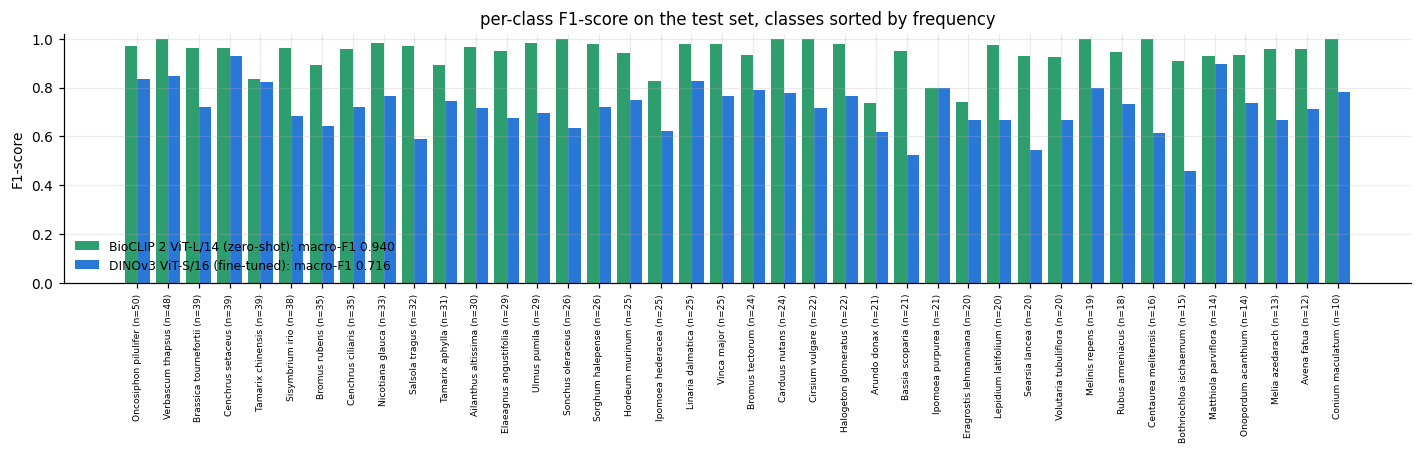

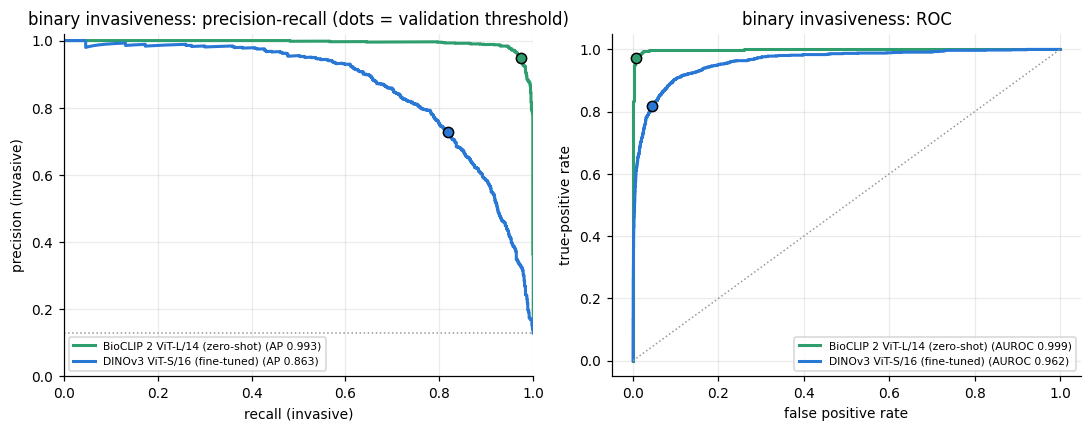

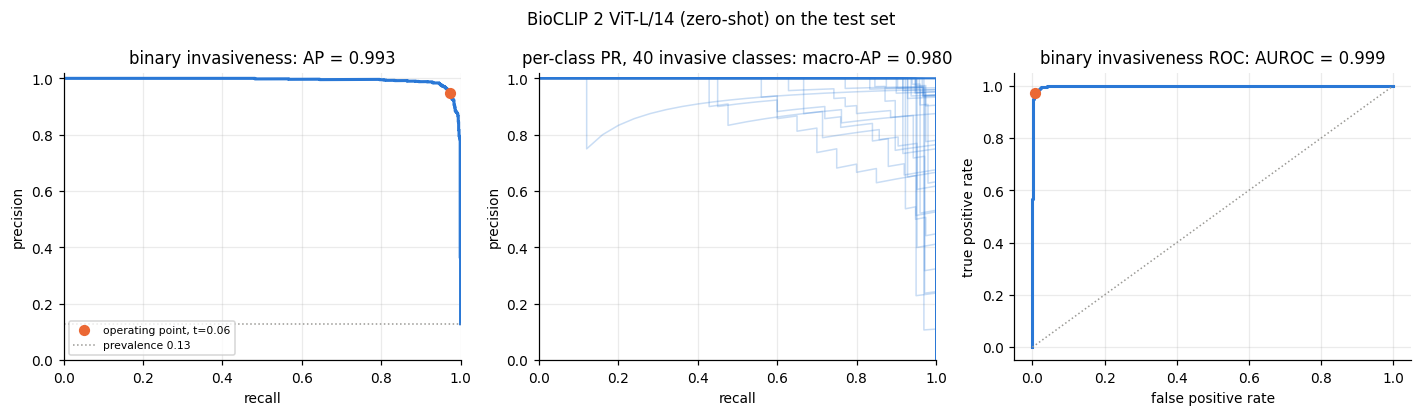

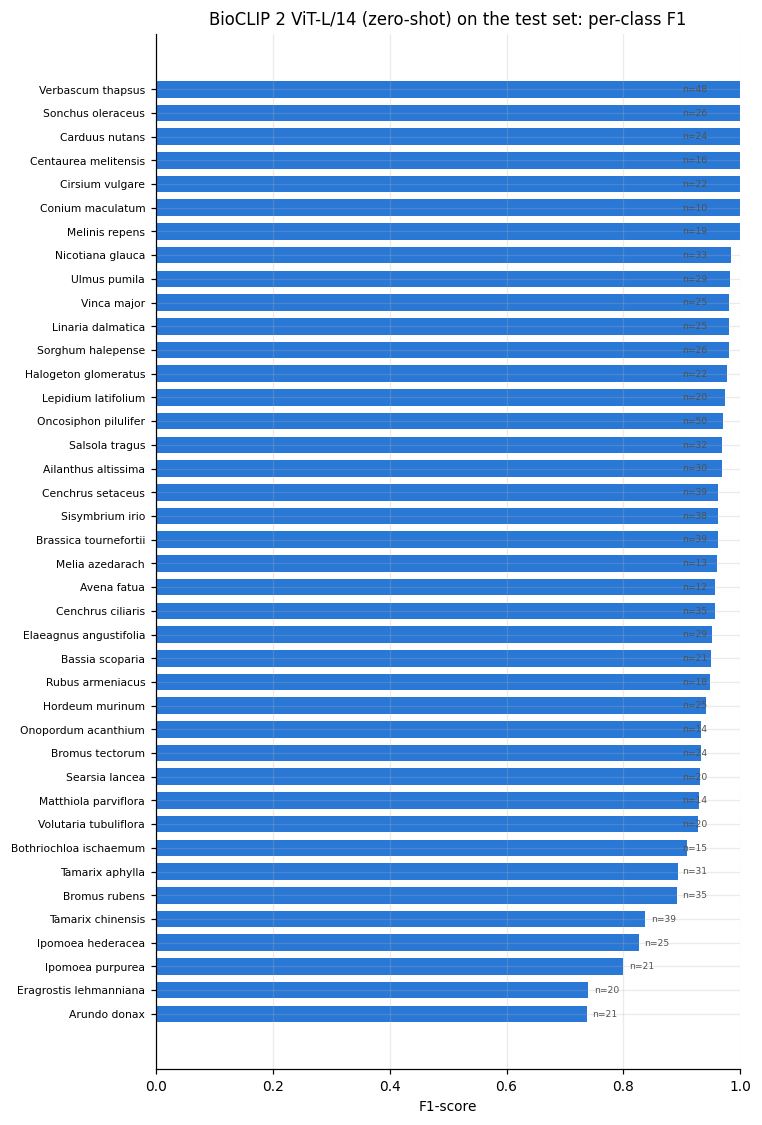

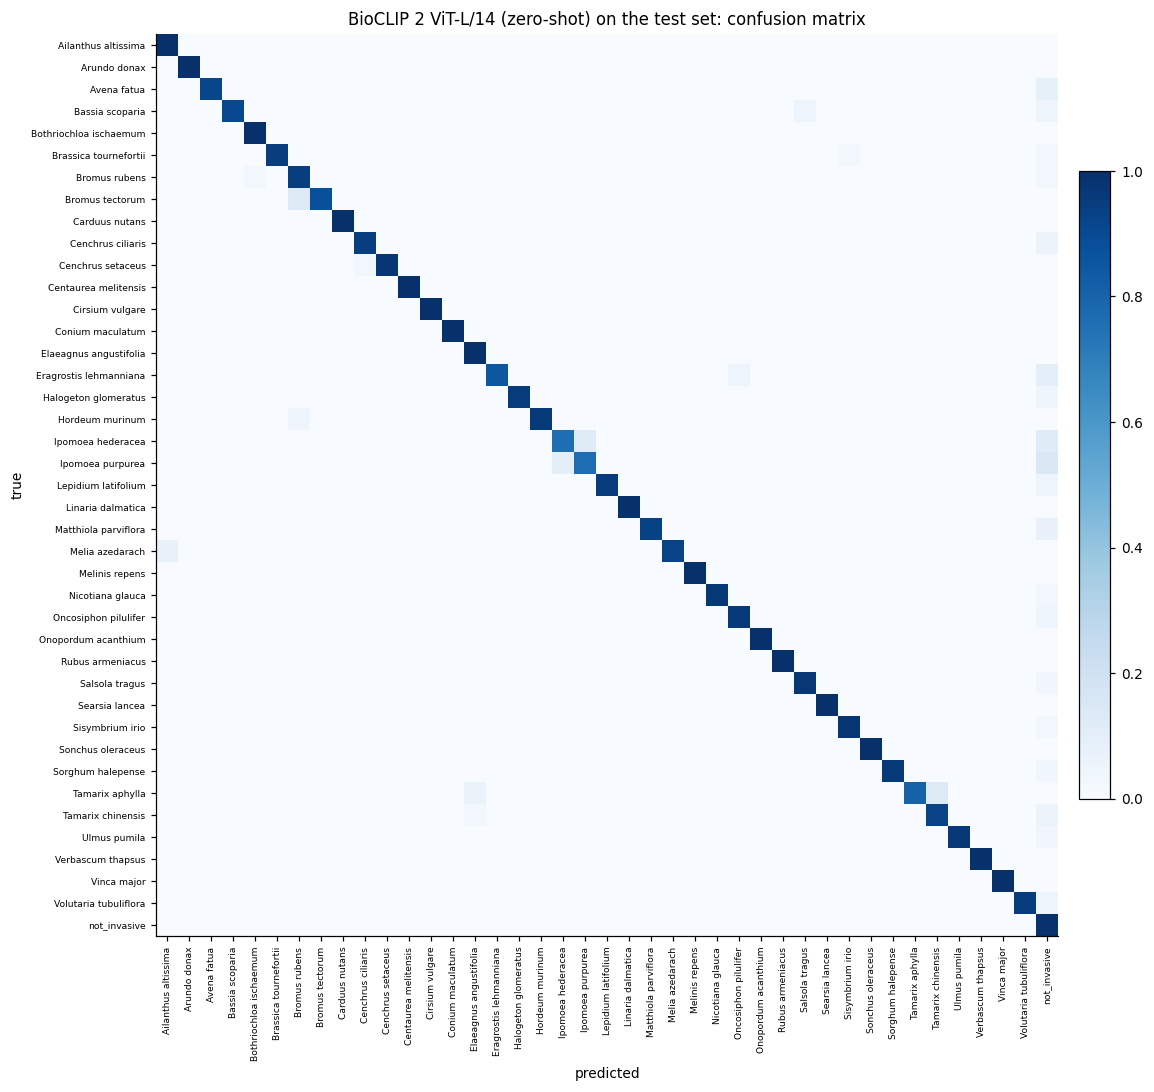

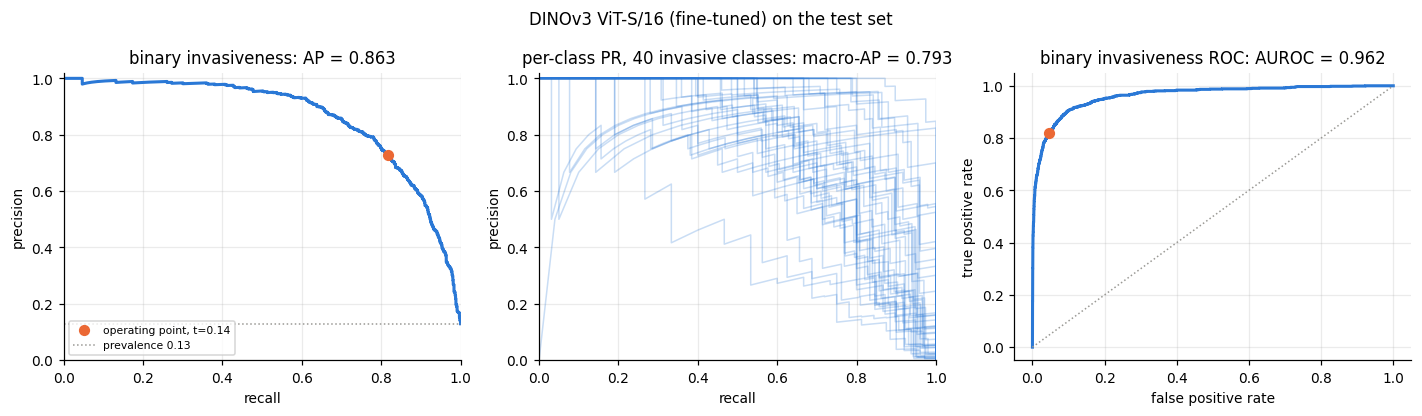

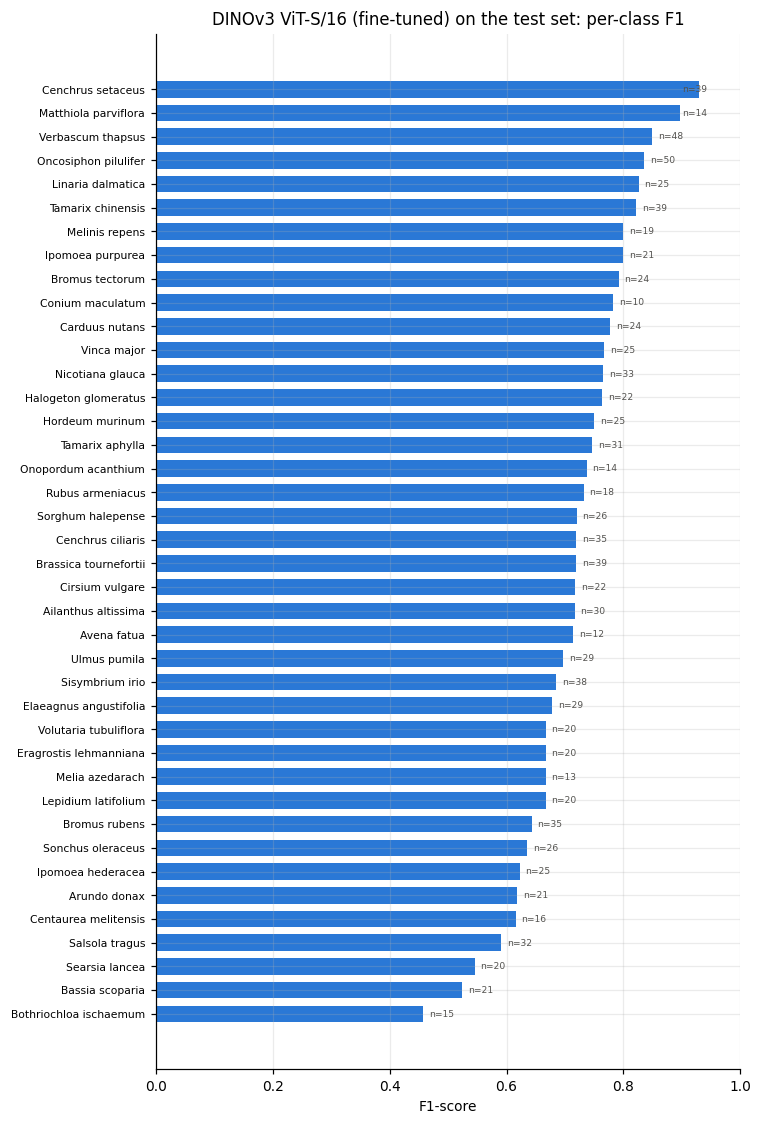

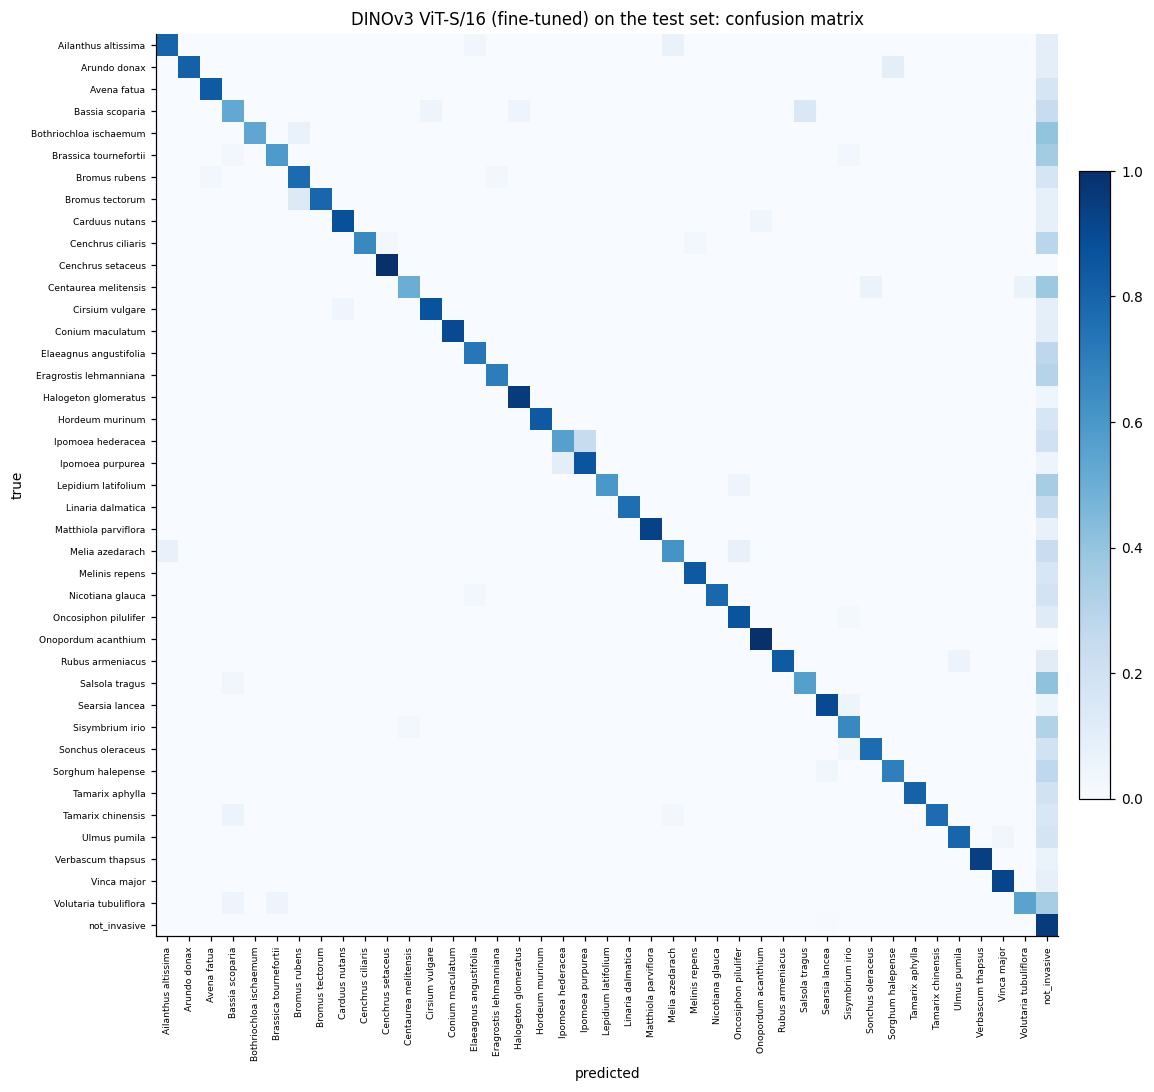

In [22]:
# per-class F1 on test, the two models side by side (classes sorted by test support)
support = test_df["label"].value_counts()
f1 = pd.DataFrame({s: TEST_METRICS[s]["per_class_f1"][:N_INVASIVE] for s in SCORERS}, index=INVASIVE_CLASSES)
f1 = f1.loc[sorted(INVASIVE_CLASSES, key=lambda c: -support.get(c, 0))]
f1.to_csv(OUT_DIR / "per_class_f1_test.csv")
fig, ax = plt.subplots(figsize=(13, 4.2))
x = np.arange(N_INVASIVE); w = 0.8 / len(SCORERS)
for j, s in enumerate(SCORERS):
    ax.bar(x + (j - (len(SCORERS) - 1) / 2) * w, f1[s].values, width=w, color=SERIES_COLORS.get(s, C_GRAY), label=f"{SCORERS[s].label}: macro-F1 {TEST_METRICS[s]['macro_f1_invasive']:.3f}")
ax.set_xticks(x); ax.set_xticklabels([f"{c} (n={support.get(c, 0)})" for c in f1.index], rotation=90, fontsize=6)
ax.set_ylim(0, 1.02); ax.set_ylabel("F1-score"); ax.set_title("per-class F1-score on the test set, classes sorted by frequency"); ax.legend(fontsize=8, frameon=False, loc="lower left")
fig.tight_layout(); fig.savefig(OUT_DIR / "per_class_f1_test.png"); plt.show()

# binary invasive detection: PR and ROC of the two models on one pair of axes
is_inv = y_test < N_INVASIVE
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for s in SCORERS:
    p = TEST_PROBS[s]; score = p.max(1); m = TEST_METRICS[s]; c = SERIES_COLORS.get(s, C_GRAY)
    pr_p, pr_r, _ = precision_recall_curve(is_inv, score); axes[0].plot(pr_r, pr_p, color=c, lw=2, label=f"{SCORERS[s].label} (AP {m['bin_ap_invasive']:.3f})")
    axes[0].scatter([m["bin_recall_invasive"]], [m["bin_precision_invasive"]], color=c, edgecolors="black", s=45, zorder=4)
    fpr, tpr, _ = roc_curve(is_inv, score); axes[1].plot(fpr, tpr, color=c, lw=2, label=f"{SCORERS[s].label} (AUROC {m['bin_auroc_invasive']:.3f})")
    fpr_t = float((~is_inv & (score >= m["threshold"])).sum() / max((~is_inv).sum(), 1))
    axes[1].scatter([fpr_t], [m["bin_recall_invasive"]], color=c, edgecolors="black", s=45, zorder=4)
axes[0].axhline(is_inv.mean(), color=C_GRAY, ls=":", lw=1); axes[0].set_xlabel("recall (invasive)"); axes[0].set_ylabel("precision (invasive)")
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1.02); axes[0].set_title("binary invasiveness: precision-recall (dots = validation threshold)"); axes[0].legend(fontsize=7, loc="lower left")
axes[1].plot([0, 1], [0, 1], color=C_GRAY, ls=":", lw=1); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true-positive rate")
axes[1].set_title("binary invasiveness: ROC"); axes[1].legend(fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(OUT_DIR / "pr_roc_test.png"); plt.show()

# per-model figures, written to final_test/<series>/
for s in SCORERS:
    ttl = f"{SCORERS[s].label} on the test set"
    plot_pr_roc(TEST_PROBS[s], y_test, TEST_METRICS[s], OUT_DIR / s, ttl)
    plot_per_class_f1(TEST_METRICS[s], OUT_DIR / s, support, f"{ttl}: per-class F1")
    plot_confusion(TEST_METRICS[s], OUT_DIR / s, f"{ttl}: confusion matrix")

### 11b. Where the errors are

The `not_invasive` photos come in four groups; which of them each model flags as invasive, and how often an invasive photo is missed or confused with another invasive class.

n  correct  left unflagged (missed)  \
series   group                                                         
bioclip2 invasive             1025   0.9522                   0.0263   
         native_background    5891   0.9966                      NaN   
         introduced_unlisted   724   0.9751                      NaN   
         listed_not_invasive   193   0.9948                      NaN   
         native_listed          98   0.8469                      NaN   
finetune invasive             1025   0.7698                   0.1824   
         native_background    5891   0.9618                      NaN   
         introduced_unlisted   724   0.9061                      NaN   
         listed_not_invasive   193   0.9896                      NaN   
         native_listed          98   0.8265                      NaN   

                              wrong invasive class  \
series   group                                       
bioclip2 invasive                           0.0215   
         native_background                     NaN   
         introduced_unlisted                   NaN   
         listed_not_invasive                   NaN   
         native_listed                         NaN   
finetune invasive                           0.0478   
         native_background                     NaN   
         introduced_unlisted                   NaN   
         listed_not_invasive                   NaN   
         native_listed                         NaN   

                              flagged as invasive (false positive)  
series   group                                                      
bioclip2 invasive                                              NaN  
         native_background                                  0.0034  
         introduced_unlisted                                0.0249  
         listed_not_invasive                                0.0052  
         native_listed                                      0.1531  
finetune invasive                                              NaN  
         native_background                                  0.0382  
         introduced_unlisted                                0.0939  
         listed_not_invasive                                0.0104  
         native_listed                                      0.1735

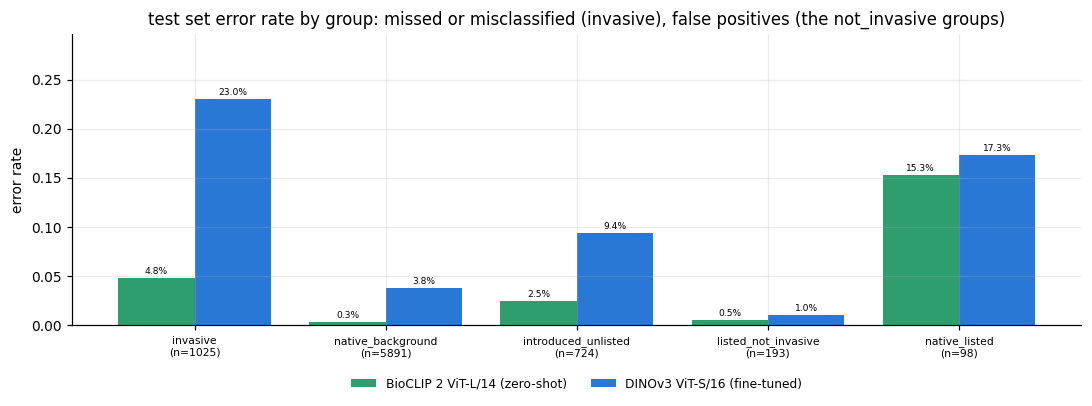

In [23]:
rows = []
for s in SCORERS:
    p = TEST_PROBS[s]; pred = TEST_METRICS[s]["_pred"]; d = test_df
    for g in GROUP_ORDER:
        mask = (d["group"] == g).to_numpy()
        if not mask.any():
            continue
        if g == "invasive":
            yg = y_test[mask]; pg = pred[mask]
            rows.append({"series": s, "group": g, "n": int(mask.sum()), "correct": float((pg == yg).mean()),
                         "left unflagged (missed)": float((pg == N_INVASIVE).mean()), "wrong invasive class": float(((pg != yg) & (pg != N_INVASIVE)).mean())})
        else:
            rows.append({"series": s, "group": g, "n": int(mask.sum()), "correct": float((pred[mask] == N_INVASIVE).mean()),
                         "flagged as invasive (false positive)": float((pred[mask] != N_INVASIVE).mean())})
errors = pd.DataFrame(rows).set_index(["series", "group"])
errors.to_csv(OUT_DIR / "errors_by_group_test.csv")
display(errors.round(4))

fig, ax = plt.subplots(figsize=(10, 3.8))
groups = [g for g in GROUP_ORDER if g in errors.index.get_level_values("group")]
x = np.arange(len(groups)); w = 0.8 / len(SCORERS)
for j, s in enumerate(SCORERS):
    vals = [1 - errors.loc[(s, g), "correct"] for g in groups]
    bars = ax.bar(x + (j - (len(SCORERS) - 1) / 2) * w, vals, width=w, color=SERIES_COLORS.get(s, C_GRAY), label=SCORERS[s].label)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.004, f"{v:.1%}", ha="center", fontsize=6)
ax.set_xticks(x); ax.set_xticklabels([f"{g}\n(n={int(errors.loc[(list(SCORERS)[0], g), 'n'])})" for g in groups], fontsize=7)
ax.set_ylabel("error rate"); ax.set_title("test set error rate by group: missed or misclassified (invasive), false positives (the not_invasive groups)")
ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=len(SCORERS))
ax.set_ylim(0, max(0.05, (1 - errors["correct"]).max() * 1.2 + 0.02))
fig.tight_layout(); fig.savefig(OUT_DIR / "errors_by_group_test.png", bbox_inches="tight"); plt.show()

## 12. Accuracy against inference runtime

Test set top-1 accuracy and macro-F1 next to the inference cost measured in Section 10, per image and for the whole test set, on the same device with the same batch size and the same mirror-TTA.

In [26]:
timing_table = pd.DataFrame({s: {"label": SCORERS[s].label, "candidate": SCORERS[s].candidate, "params_M": TIMING[s]["params_M"],
                                 "top1_acc_all": TEST_METRICS[s]["top1_acc_all"], "macro_f1_invasive": TEST_METRICS[s]["macro_f1_invasive"],
                                 "ms_per_image": TIMING[s]["ms_per_image"], "images_per_second": TIMING[s]["images_per_second"],
                                 "seconds_test_set": TIMING[s]["seconds"], "n_images": TIMING[s]["n_images"], "batch_size": TIMING[s]["batch_size"],
                                 "tta_hflip": TIMING[s]["tta_hflip"], "amp": TIMING[s]["amp"], "peak_gpu_memory_GiB": TIMING[s]["peak_gpu_memory_GiB"],
                                 "device": TIMING[s]["device"]} for s in SCORERS}).T
timing_table.to_csv(OUT_DIR / "timing.csv")

accuracy_vs_runtime = pd.DataFrame({SCORERS[s].label: {"parameters (M)": TIMING[s]["params_M"],
                                                       "top-1 accuracy": TEST_METRICS[s]["top1_acc_all"], "macro-F1 (invasive)": TEST_METRICS[s]["macro_f1_invasive"],
                                                       "ms per image": TIMING[s]["ms_per_image"], "images per second": TIMING[s]["images_per_second"],
                                                       "seconds elapsed": TIMING[s]["seconds"], "peak GPU memory (GiB)": TIMING[s]["peak_gpu_memory_GiB"]}
                                    for s in SCORERS}).T.astype(float)
accuracy_vs_runtime.to_csv(OUT_DIR / "accuracy_vs_runtime.csv")
print(f"test set: {TIMING[next(iter(SCORERS))]['n_images']} images, batches of {EVAL_BATCH_SIZE}, mirror TTA, {DEVICE_NAME}"
      + (f", {TIMING_REPEATS} timed passes (minimum reported)" if TIMING_REPEATS > 1 else ""))
display(accuracy_vs_runtime.round(4))

test set: 7931 images, batches of 128, mirror TTA, Tesla T4


,parameters (M),top-1 accuracy,macro-F1 (invasive),ms per image,images per second,seconds elapsed,peak GPU memory (GiB)
BioCLIP 2 ViT-L/14 (zero-shot),303.9662,0.9870,0.9399,147.9290,6.7600,1173.2247,3.7309
DINOv3 ViT-S/16 (fine-tuned),21.6273,0.9309,0.7163,10.4775,95.4427,83.0970,1.0305


## 13. Unseen species

`test_unseen.csv` holds photos of hold-out species that no model saw in training and that are not on the invasive list, all labeled `not_invasive`. Top-1 accuracy here is the share of these photos the model leaves unflagged at its validation threshold; a model that only recognizes what it was trained on should be close to 100%. For a flagged photo, the invasive class it was mistaken for is recorded in `unseen_predictions.csv`.

bioclip2 unseen pass 1/1:   0%|          | 0/7 [00:00<?, ?batch/s]

finetune unseen pass 1/1:   0%|          | 0/7 [00:00<?, ?batch/s]

,model,photos,hold-out species,top-1 accuracy,flagged as invasive,species with at least one flag
series,,,,,,
bioclip2,bioclip2_zeroshot_full/00_baseline,792,30,0.9710,23,7
finetune,dinov3_vits16/04_pool_cls_patchmean,792,30,0.9179,65,15


bioclip2: 23 of 792 unseen-species photos flagged; most often as Sonchus oleraceus (13), Halogeton glomeratus (5), Searsia lancea (1)
finetune: 65 of 792 unseen-species photos flagged; most often as Conium maculatum (11), Halogeton glomeratus (8), Salsola tragus (7)


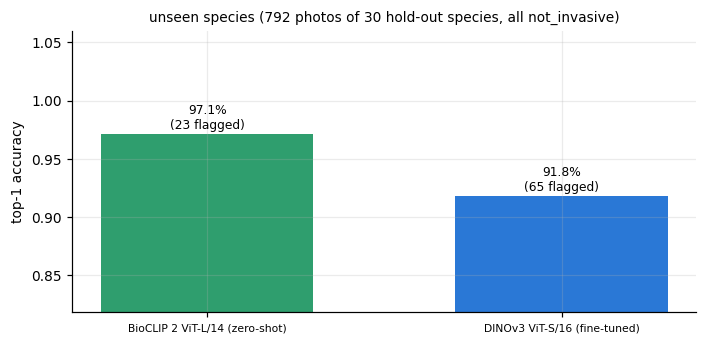

In [27]:
UNSEEN = {}
rows = []
for s, sc in SCORERS.items():
    _, unseen_images = eval_images_cache(sc.cfg)
    probs, _ = timed_scoring(sc, unseen_images, EVAL_BATCH_SIZE, 1, desc=f"{s} unseen")
    pred = predict_not_invasive(probs, sc.threshold)
    d = unseen_df
    out = pd.DataFrame({"observation_id": d["observation_id"].to_numpy(), "scientific_name": d["scientific_name"].to_numpy(), "pred": [ALL_LABELS[i] for i in pred],
                        "max_prob": probs.max(1), "argmax_class": [INVASIVE_CLASSES[i] for i in probs.argmax(1)]})
    out.to_csv(OUT_DIR / s / "unseen_predictions.csv", index=False)
    flagged = out[out["pred"] != NONE_LABEL]
    UNSEEN[s] = {"n": int(len(out)), "top1_acc": float((pred == N_INVASIVE).mean()), "n_flagged": int(len(flagged)),
                 "n_species": int(d["scientific_name"].nunique()), "species_with_a_flag": int(flagged["scientific_name"].nunique()),
                 "flags_by_predicted_class": flagged["pred"].value_counts().to_dict()}
    rows.append({"series": s, "model": sc.candidate, "photos": len(out), "hold-out species": UNSEEN[s]["n_species"],
                 "top-1 accuracy": UNSEEN[s]["top1_acc"], "flagged as invasive": UNSEEN[s]["n_flagged"],
                 "species with at least one flag": UNSEEN[s]["species_with_a_flag"]})
unseen_results = pd.DataFrame(rows).set_index("series")
unseen_results.to_csv(OUT_DIR / "unseen_results.csv")
display(unseen_results.style.format({"top-1 accuracy": "{:.4f}"}))
for s in SCORERS:
    top = sorted(UNSEEN[s]["flags_by_predicted_class"].items(), key=lambda kv: -kv[1])[:3]
    print(f"{s}: {UNSEEN[s]['n_flagged']} of {UNSEEN[s]['n']} unseen-species photos flagged" + (f"; most often as {', '.join(f'{c} ({n})' for c, n in top)}" if top else ""))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
vals = [UNSEEN[s]["top1_acc"] for s in SCORERS]
bars = ax.bar([SCORERS[s].label for s in SCORERS], vals, color=[SERIES_COLORS.get(s, C_GRAY) for s in SCORERS], width=0.6)
for b, v, s in zip(bars, vals, SCORERS):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.1%}\n({UNSEEN[s]['n_flagged']} flagged)", ha="center", fontsize=8)
ax.set_ylim(max(0, min(vals) - 0.1), 1.06); ax.set_ylabel("top-1 accuracy"); ax.tick_params(axis="x", labelsize=7)
ax.set_title(f"unseen species ({UNSEEN[next(iter(SCORERS))]['n']} photos of {UNSEEN[next(iter(SCORERS))]['n_species']} hold-out species, all not_invasive)", fontsize=9)
fig.tight_layout(); fig.savefig(OUT_DIR / "unseen_top1.png"); plt.show()

## 14. Record everything

`final_test/final_results.json`: per series the model, how it was trained for the test (or that it was not), its threshold, every test metric, the timing and the unseen-species result, plus the split sizes. The CSV tables and figures were written by the sections above.

In [28]:
results = {}
for s, sc in SCORERS.items():
    rec = MODELS[s]
    results[s] = {"label": sc.label, "series_label": rec["label"], "candidate": rec["candidate"], "kind": rec["kind"], "backbone": rec["backbone"], "backbone_display": rec.get("backbone_display"),
                  "test_protocol": rec["test_protocol"], "chosen_by": rec["chosen_by"], "note": rec.get("note", ""),
                  "training": ({"trained_on": "train+val", **TRAINED[s]["summary"], "weights": str((OUT_DIR / s / "final.pt").relative_to(RUNS_DIR)),
                                "changes_vs_finetune_baseline": rec.get("changes_vs_finetune_baseline")} if s in TRAINED
                               else {"trained_on": None, "weights": rec["weights_file"], "method": FROZEN[s]["method"].describe()}),
                  "threshold": sc.threshold, "threshold_source": "tuned on validation by the chosen run",
                  "val_metrics": rec["metrics"], "test_metrics": scalars(TEST_METRICS[s]),
                  "test_per_class_f1": dict(zip(ALL_LABELS, TEST_METRICS[s]["per_class_f1"])),
                  "timing": TIMING[s], "unseen": UNSEEN[s], "files": sorted(p.name for p in (OUT_DIR / s).iterdir())}
final_results = {
    "evaluated_at": datetime.datetime.now().isoformat(timespec="seconds"), "runs_dir": str(RUNS_DIR.resolve()), "device": DEVICE_NAME,
    "selection_file": str((SEL_DIR / "final_models.json").resolve()), "selected_at": FINAL["selected_at"],
    "eval_batch_size": EVAL_BATCH_SIZE, "timing_repeats": TIMING_REPEATS,
    "splits": {k: {c: (float(v) if c == "invasive_share" else int(v)) for c, v in r.items()} for k, r in split_overview.to_dict("index").items()},
    "models": results,
    "notes": ["The fine-tuned model was trained on train + val with the hyperparameters of the chosen iteration for the full schedule; the weights after the last epoch are used.",
              "Thresholds are the ones tuned on validation by the chosen runs (threshold_val); nothing was tuned on test or test_unseen.",
              "Timing: one untimed warm-up batch, then the whole test set in batches of eval_batch_size with mirror TTA, GPU synchronized; image decoding excluded.",
              "unseen.top1_acc is the share of test_unseen photos (all not_invasive) left unflagged at the threshold."],
}
json.dump(final_results, open(OUT_DIR / "final_results.json", "w"), indent=1, default=str)

print(f"{'series':<9} {'model':<40} {'val F1':>7} {'test F1':>8} {'val top1':>9} {'test top1':>10} {'ms/img':>7} {'unseen top1':>12}")
for s, r in results.items():
    print(f"{s:<9} {r['candidate']:<40} {r['val_metrics']['macro_f1_invasive']:7.4f} {r['test_metrics']['macro_f1_invasive']:8.4f} "
          f"{r['val_metrics']['top1_acc_all']:9.4f} {r['test_metrics']['top1_acc_all']:10.4f} {r['timing']['ms_per_image']:7.2f} {r['unseen']['top1_acc']:12.4f}")
print("\nwritten to", OUT_DIR.resolve(), ":", sorted(p.name for p in OUT_DIR.iterdir()))

series    model                                     val F1  test F1  val top1  test top1  ms/img  unseen top1
bioclip2  bioclip2_zeroshot_full/00_baseline        0.9668   0.9399    0.9823     0.9870  147.93       0.9710
finetune  dinov3_vits16/04_pool_cls_patchmean       0.7514   0.7163    0.8826     0.9309   10.48       0.9179

written to /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/modeling_runs/final_test : ['accuracy_vs_runtime.csv', 'bioclip2', 'class_counts.csv', 'errors_by_group_test.csv', 'errors_by_group_test.png', 'final_results.json', 'finetune', 'per_class_f1_test.csv', 'per_class_f1_test.png', 'pr_roc_test.png', 'split_overview.csv', 'split_overview.png', 'test_metrics.csv', 'test_vs_val.csv', 'timing.csv', 'unseen_results.csv', 'unseen_top1.png']
